<a href="https://colab.research.google.com/github/bubai-jkc/examples/blob/main/supervised%20and%20unimatch.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
#!/usr/bin/env python3
"""
plantseg_audit.py -- reproducible dataset audit for PlantSeg.

Dataset : PlantSeg (Wei et al., Scientific Data 13:205, 2026)
          https://doi.org/10.5281/zenodo.17719108   (CC BY-NC 4.0)
Input   : plantseg.zip, or an already-extracted plantseg/ directory
Outputs : plantseg_audit.json   -- every measurement below
          plantseg_splits.json  -- clean eval subsets + nested label budgets
Runtime : ~12 min, CPU only.  Fully deterministic: reruns are byte-identical.

Checks, in order:
  1 file inventory vs Metadata.csv
  2 COCO annotation integrity
  3 mask encoding; Mask ratio validated against a full pixel scan
  4 lesion-area distribution; the frozen quartile cuts
  5 polygon geometry validated against the masks
  6 source-URL screen for cross-split reuse
  7 perceptual-hash near-duplicate scan, with threshold sensitivity
  8 clean evaluation subsets, and whether decontamination biases them
  9 nested, quartile-stratified labelled budgets
"""
import os, re, csv, json, collections, subprocess
import numpy as np
from PIL import Image, ImageDraw
from scipy.fft import dctn

# ------------------------------- config --------------------------------
ZIP        = "/content/drive/MyDrive/Colab Notebooks/plantseg.zip"
ROOT       = "/content/my_images"          # extraction target
SAVE       = "/content/drive/MyDrive"      # where the two json files go
SPLITS     = ["train", "val", "test"]
HASH_THRESH, HASH_WIDEST = 6, 10           # Hamming on a 64-bit pHash
LABEL_SEED = 42                            # fixes WHICH images are labelled
BUDGETS    = {"05pct": 268, "10pct": 537, "20pct": 1073,
              "50pct": 2684, "100pct": 5367}
DS = f"{ROOT}/plantseg"
Image.MAX_IMAGE_PIXELS = None
R = {}                                     # every reported number lands here

try:                                       # optional: Colab only
    from google.colab import drive
    drive.mount("/content/drive", force_remount=True)
except Exception:
    pass

if not os.path.isdir(DS) or not os.listdir(DS):
    print("extracting ...")
    p = subprocess.run(["unzip", "-q", ZIP, "-d", ROOT], capture_output=True, text=True)
    if p.returncode != 0:
        raise SystemExit(f"unzip failed ({p.returncode}): {p.stderr[-500:]}")
print("dataset at", DS)

# --------------------- 1. inventory vs Metadata.csv --------------------
print("=" * 72, "\n1. INVENTORY")
disk = {s: sorted({os.path.splitext(f)[0] for f in os.listdir(f"{DS}/images/{s}")
                   if f.lower().endswith(".jpg")}
                  & {os.path.splitext(f)[0] for f in os.listdir(f"{DS}/annotations/{s}")
                     if f.lower().endswith(".png")}) for s in SPLITS}
split_of = {st: s for s in SPLITS for st in disk[s]}
stems = sorted(split_of)
R["paired"] = {s: len(disk[s]) for s in SPLITS}
R["n_images"] = len(stems)
print("  paired:", R["paired"], " total", R["n_images"])
for i in range(3):
    for j in range(i + 1, 3):
        ov = set(disk[SPLITS[i]]) & set(disk[SPLITS[j]])
        if ov: print(f"  !! {SPLITS[i]}/{SPLITS[j]} share {len(ov)}")

meta = {os.path.splitext(r["Name"])[0]: r for r in
        csv.DictReader(open(f"{DS}/Metadata.csv", encoding="utf-8-sig", newline=""))}
frac = {k: float(v["Mask ratio"]) for k, v in meta.items()}       # verified in step 3
R["metadata_rows"] = len(meta)
R["meta_file_mismatch"] = [len(set(meta) - set(stems)), len(set(stems) - set(meta))]
R["n_plants"] = len({r["Plant"] for r in meta.values()})
R["n_diseases"] = len({r["Disease"] for r in meta.values()})
R["licences"] = dict(collections.Counter(r["License"] for r in meta.values()))
res = {k: tuple(int(x) for x in v["Resolution"].lower().split("x")) for k, v in meta.items()}
px = np.array([w * h for w, h in res.values()])
R["resolution"] = dict(min_px=int(px.min()), max_px=int(px.max()),
                       median_px=int(np.median(px)),
                       under_0_1MP=int((px < 1e5).sum()), over_2MP=int((px > 2e6).sum()))
R["label_file_consistent"] = all(
    r["Label file"] == os.path.splitext(r["Name"])[0] + ".png" for r in meta.values())
print(f"  rows {R['metadata_rows']}  mismatch {R['meta_file_mismatch']}"
      f"  plants {R['n_plants']}  diseases {R['n_diseases']}  licences {R['licences']}")
print(f"  resolution {R['resolution']}   Label file consistent "
      f"{R['label_file_consistent']}")

# ----------------------- 2. COCO annotations ---------------------------
print("=" * 72, "\n2. COCO ANNOTATIONS")
n_lesion, img_cat, poly_of, wh = {}, {}, {}, {}
R["coco"] = {}
for s in SPLITS:
    J = json.load(open(f"{DS}/annotation_{s}.json"))
    ids = {im["id"]: os.path.splitext(im["file_name"])[0] for im in J["images"]}
    for im in J["images"]:
        st = os.path.splitext(im["file_name"])[0]
        wh[st] = (im["width"], im["height"])
        poly_of.setdefault(st, []); n_lesion.setdefault(st, 0)
    orph = 0
    for a in J["annotations"]:
        st = ids.get(a["image_id"])
        if st is None:
            orph += 1; continue
        n_lesion[st] += 1
        img_cat.setdefault(st, set()).add(int(a["category_id"]))
        poly_of[st].append(a["segmentation"])
    R["coco"][s] = dict(images=len(ids), annotations=len(J["annotations"]),
                        kept=len(J["annotations"]) - orph, orphan=orph,
                        categories=len(J.get("categories") or []),
                        not_on_disk=len(set(ids.values()) - set(disk[s])))
    print(f"  {s:5s} {R['coco'][s]}")
nl = np.array(sorted(n_lesion.values()))
R["lesions_per_image"] = dict(min=int(nl.min()), median=int(np.median(nl)),
                              mean=round(float(nl.mean()), 2), max=int(nl.max()),
                              exactly_one=int((nl == 1).sum()), over_ten=int((nl > 10).sum()))
print("  lesions/image", R["lesions_per_image"])
print("  NOTE: orphan annotations reference images withdrawn from this release;")
print("        build file lists from disk or Metadata.csv, never from these JSONs.")

# ------------------- 3. mask encoding + validation ---------------------
print("=" * 72, "\n3. MASK SCAN")
present = np.zeros(4096, dtype=np.int64)
ndist, true_frac, fg_of, bad = collections.Counter(), {}, {}, []
for s in SPLITS:
    for k, st in enumerate(disk[s], 1):
        a = np.asarray(Image.open(f"{DS}/annotations/{s}/{st}.png"))
        if a.ndim != 2 or int(a.max()) >= 4096:
            bad.append(st); continue
        h = np.bincount(a.ravel(), minlength=4096)
        nz = np.nonzero(h)[0]
        present[nz] += 1; ndist[len(nz)] += 1
        true_frac[st] = float(h[1:].sum()) / float(h.sum())
        fg_of[st] = {int(v) for v in nz if v > 0}
        if k % 2000 == 0: print(f"    {s} {k}/{len(disk[s])}")
vals = np.nonzero(present)[0]
dev = np.array([abs(true_frac[k] - frac[k]) for k in true_frac])
off = collections.Counter(
    next(iter(fg_of[st])) - next(iter(img_cat[st]))
    for st in img_cat if st in fg_of and len(img_cat[st]) == 1 and len(fg_of[st]) == 1)
R["mask"] = dict(values=[int(vals.min()), int(vals.max())], n_values=len(vals),
                 masks_with_255=int(present[255]),
                 distinct_values_per_mask=dict(sorted(ndist.items())),
                 unreadable=bad,
                 maskratio_max_abs_error=float(dev.max()),
                 mask_minus_category_id=dict(off.most_common(3)))
print(f"  values {R['mask']['values']}  ({len(vals)} distinct)   "
      f"255 in {R['mask']['masks_with_255']} masks")
print(f"  distinct values per mask {R['mask']['distinct_values_per_mask']}")
print(f"  Mask ratio vs pixel scan: max abs error {dev.max():.2e}  -> column is exact")
print(f"  (mask value - category_id) {R['mask']['mask_minus_category_id']}")
print("  BINARY RULE: y = (mask > 0).  0 is background; no ignore index exists.")

# -------------- 4. lesion area, quartile cuts, class sizes -------------
print("=" * 72, "\n4. LESION AREA + CLASS SIZES")
tr = np.array([frac[s] for s in disk["train"]])
cuts = np.percentile(tr, [25, 50, 75]).tolist()
R["train_area"] = dict(n=len(tr), mean=round(float(tr.mean()), 4),
                       median=round(float(np.median(tr)), 4),
                       min=round(float(tr.min()), 5), max=round(float(tr.max()), 4),
                       quartile_cuts=[round(c, 6) for c in cuts],
                       under_1pct=int((tr < .01).sum()), under_2pct=int((tr < .02).sum()),
                       under_5pct=int((tr < .05).sum()), under_10pct=int((tr < .10).sum()))
print("  ", R["train_area"])
dis_tr = collections.Counter(meta[s]["Disease"] for s in disk["train"])
cc = np.array(sorted(dis_tr.values()))
cov = collections.defaultdict(collections.Counter)
for st, sp in split_of.items(): cov[meta[st]["Disease"]][sp] += 1
R["class_sizes"] = dict(n_diseases=len(dis_tr), min=int(cc.min()),
                        median=int(np.median(cc)), max=int(cc.max()),
                        under_10=int((cc < 10).sum()), under_20=int((cc < 20).sum()),
                        missing_from={sp: [d for d, v in cov.items() if v[sp] == 0]
                                      for sp in SPLITS})
print("  ", R["class_sizes"])
print("  CONSEQUENCE: stratify label budgets by lesion-area quartile, not by disease.")

# -------------------- 5. polygons validated vs masks -------------------
print("=" * 72, "\n5. POLYGONS vs MASKS")
pv, over, big = {}, [], []
for k, st in enumerate(stems, 1):
    W, H = wh[st]
    xs, ys = [], []
    canvas = Image.new("L", (W, H), 0); dr = ImageDraw.Draw(canvas)
    for seg in poly_of.get(st, []):
        for p in seg:
            if len(p) >= 6:
                xs += p[0::2]; ys += p[1::2]
                dr.polygon(list(zip(p[0::2], p[1::2])), fill=1)
    pf = float(np.asarray(canvas, dtype=np.uint8).sum()) / (W * H)
    fit = bool(xs) and max(xs) <= W + 1 and max(ys) <= H + 1 \
          and min(xs) >= -1 and min(ys) >= -1
    diff = pf - frac[st]
    pv[st] = dict(split=split_of[st], n=len(poly_of.get(st, [])), poly=round(pf, 6),
                  mask=frac[st], diff=round(diff, 6), fit=fit,
                  usable=bool(fit and abs(diff) <= 0.01 and xs))
    if not fit: over.append(st)
    elif abs(diff) > 0.01: big.append(st)
    if k % 2000 == 0: print(f"    {k}/{len(stems)}")
R["polygons"] = dict(usable=sum(1 for v in pv.values() if v["usable"]), total=len(pv),
                     coord_overflow=len(over), large_disagreement=len(big),
                     coord_overflow_stems=sorted(over),
                     no_polygon=[k for k, v in pv.items() if v["n"] == 0],
                     mask_covers_frame=[k for k, v in frac.items() if v >= 0.99999])
print("  ", {k: v for k, v in R["polygons"].items() if not k.endswith("stems")})
print("  CONSEQUENCE: masks are ground truth; polygons are auxiliary labels,")
print("               usable only on the validated subset.")

# ----------------------- 6. source-URL screen --------------------------
print("=" * 72, "\n6. SOURCE-URL SCREEN")
def nurl(u):
    u = re.sub(r"^www\.", "", re.sub(r"^https?://", "", str(u).strip().lower()))
    return u.rstrip("/") or None
by_url = collections.defaultdict(list)
for st in stems:
    u = nurl(meta[st]["URL"])
    if u: by_url[u].append(st)
cross_url = {u: v for u, v in by_url.items()
             if len(v) > 1 and len({split_of[s] for s in v}) > 1}
pu = collections.Counter(split_of[s] for v in cross_url.values() for s in v)
R["url_screen"] = dict(distinct_urls=len(by_url), groups_spanning_splits=len(cross_url),
                       pct={sp: round(100 * pu[sp] / len(disk[sp]), 2) for sp in SPLITS},
                       top_domains=dict(collections.Counter(
                           nurl(r["URL"]).split("/")[0] for r in meta.values()
                           if nurl(r["URL"])).most_common(8)))
print("  ", {k: v for k, v in R["url_screen"].items() if k != "top_domains"})
print("   top domains", R["url_screen"]["top_domains"])

# ------------------ 7. perceptual-hash duplicate scan ------------------
print("=" * 72, "\n7. pHASH DUPLICATE SCAN")
def phash(a):
    D = dctn(a, norm="ortho")[:8, :8].copy(); D[0, 0] = 0.0
    return (D > np.median(D)).ravel()

N = len(stems)
H = np.zeros((N, 64), bool); HF = np.zeros((N, 64), bool)
for i, st in enumerate(stems):
    # NOTE: PIL's draft() must NOT be used here. It snaps JPEG decoding to a
    # 1/2, 1/4 or 1/8 scale chosen from the SOURCE size, so two different-sized
    # copies of one photograph alias differently and stop matching -- which is
    # precisely the case this scan exists to find.
    a = np.asarray(Image.open(f"{DS}/images/{split_of[st]}/{st}.jpg")
                   .convert("L").resize((32, 32), Image.BILINEAR), dtype=np.float32)
    H[i], HF[i] = phash(a), phash(a[:, ::-1])       # HF = mirrored, for flip matching
    if (i + 1) % 2000 == 0: print(f"    hashed {i+1}/{N}")

PK, PKF = np.packbits(H, axis=1), np.packbits(HF, axis=1)
POP = np.unpackbits(np.arange(256, dtype=np.uint8)[:, None], axis=1).sum(1).astype(np.uint8)
pairs = []
for i0 in range(0, N, 512):
    sl = PK[i0:i0 + 512]
    d = np.minimum(POP[sl[:, None, :] ^ PK[None, :, :]].sum(2),
                   POP[sl[:, None, :] ^ PKF[None, :, :]].sum(2))
    ii, jj = np.nonzero(d <= HASH_WIDEST)
    for a_, b_ in zip(ii, jj):
        g = i0 + int(a_)
        if g < int(b_): pairs.append((g, int(b_), int(d[a_, b_])))
    print(f"    compared {min(i0+512, N)}/{N}")

def components(thr):
    par = list(range(N))
    def find(x):
        while par[x] != x: par[x] = par[par[x]]; x = par[x]
        return x
    for a_, b_, dd in pairs:
        if dd <= thr:
            ra, rb = find(a_), find(b_)
            if ra != rb: par[rb] = ra
    c = collections.defaultdict(list)
    for i in range(N): c[find(i)].append(i)
    return c

sens = {}
print(f"  pairs at Hamming <= {HASH_WIDEST}: {len(pairs)}")
print(f"  {'thr':>4} {'clusters':>9} {'unique':>8} {'test %':>8} {'val %':>8}")
for thr in (2, 4, 6, 8, 10):
    c = components(thr)
    lk = collections.Counter()
    for v in c.values():
        if len(v) > 1 and len({split_of[stems[i]] for i in v}) > 1:
            for i in v: lk[split_of[stems[i]]] += 1
    sens[thr] = dict(clusters=sum(1 for v in c.values() if len(v) > 1), unique=len(c),
                     pct={sp: round(100 * lk[sp] / len(disk[sp]), 2) for sp in SPLITS})
    print(f"  {thr:>4} {sens[thr]['clusters']:>9} {sens[thr]['unique']:>8}"
          f" {sens[thr]['pct']['test']:>7.2f}% {sens[thr]['pct']['val']:>7.2f}%")

comp = components(HASH_THRESH)
clusters = sorted([v for v in comp.values() if len(v) > 1], key=len, reverse=True)
cross = [[stems[i] for i in v] for v in clusters
         if len({split_of[stems[i]] for i in v}) > 1]
leak = collections.Counter(split_of[s] for c in cross for s in c)
same = [c for c in cross if len({meta[s]["Disease"] for s in c}) == 1]
R["dupscan"] = dict(
    threshold=HASH_THRESH, sensitivity={str(k): v for k, v in sens.items()},
    clusters=len(clusters), cross_split=len(cross), unique_photographs=len(comp),
    pct={sp: round(100 * leak[sp] / len(disk[sp]), 2) for sp in SPLITS},
    same_disease=len(same), cross_disease=len(cross) - len(same),
    url_corroborated=dict(
        same=sum(1 for c in same if len({nurl(meta[s]["URL"]) for s in c}) == 1),
        diff=sum(1 for c in cross if c not in same
                 and len({nurl(meta[s]["URL"]) for s in c}) == 1)))
print("  ", {k: v for k, v in R["dupscan"].items() if k != "sensitivity"})
print("  NOTE: for a BINARY task every cross-split cluster leaks, whatever disease")
print("        label each copy carries, so the reported figure is the full one.")

# --------- 8. groups, clean evaluation subsets, bias check -------------
print("=" * 72, "\n8. CLEAN EVALUATION SUBSETS")
idx = {s: i for i, s in enumerate(stems)}
par = list(range(N))
def find(x):
    while par[x] != x: par[x] = par[par[x]]; x = par[x]
    return x
def union(a, b):
    ra, rb = find(idx[a]), find(idx[b])
    if ra != rb: par[rb] = ra
for v in clusters:                                   # pHash clusters
    for i in v[1:]: union(stems[v[0]], stems[i])
for v in by_url.values():                            # plus same source page
    for s in v[1:]: union(v[0], s)
group_of = {s: find(idx[s]) for s in stems}
gsz = collections.Counter(collections.Counter(group_of.values()).values())
R["groups"] = dict(n_groups=len(set(group_of.values())), size_histogram=dict(sorted(gsz.items())))
print("  ", R["groups"])

clean, bias = {}, {}
tg = {group_of[s] for s in disk["train"]}
vg = {group_of[s] for s in disk["val"]}
for sp, blocked in (("val", tg), ("test", tg | vg)):
    clean[sp] = [s for s in disk[sp] if group_of[s] not in blocked]
    fa = np.array([frac[s] for s in disk[sp]])
    fc = np.array([frac[s] for s in clean[sp]])
    qa = [int(((fa > lo) & (fa <= hi)).sum()) for lo, hi in zip([-1] + cuts, cuts + [2])]
    qc = [int(((fc > lo) & (fc <= hi)).sum()) for lo, hi in zip([-1] + cuts, cuts + [2])]
    bias[sp] = dict(kept=len(clean[sp]), of=len(disk[sp]),
                    median=[round(float(np.median(fa)), 4), round(float(np.median(fc)), 4)],
                    under_5pct_pct=[round(100 * float((fa < .05).mean()), 1),
                                    round(100 * float((fc < .05).mean()), 1)],
                    quartile_counts=[qa, qc],
                    diseases=[len({meta[s]["Disease"] for s in disk[sp]}),
                              len({meta[s]["Disease"] for s in clean[sp]})])
    print(f"  {sp:5s} {bias[sp]}")
R["clean_subsets"] = bias
print("  Compare models on the FULL official split and on these subsets.")
print("  No retraining is required: only the evaluation set changes.")

# --------------- 9. nested, quartile-stratified budgets ----------------
print("=" * 72, "\n9. LABELLED BUDGETS")
def quartile(s):
    f = frac[s]
    return 0 if f <= cuts[0] else 1 if f <= cuts[1] else 2 if f <= cuts[2] else 3
rng = np.random.default_rng(LABEL_SEED)
pools = collections.defaultdict(list)
for s in disk["train"]: pools[quartile(s)].append(s)
for k in pools:
    pools[k] = [pools[k][i] for i in rng.permutation(len(pools[k]))]
ntr = len(disk["train"])
# One stratified ordering; each budget is a prefix, so nesting is structural.
tgt = {k: len(v) / ntr for k, v in pools.items()}
ptr = {k: 0 for k in pools}; cnt = {k: 0 for k in pools}; order = []
for i in range(ntr):
    k = max((k for k in pools if ptr[k] < len(pools[k])),
            key=lambda k: tgt[k] * (i + 1) - cnt[k])
    order.append(pools[k][ptr[k]]); ptr[k] += 1; cnt[k] += 1
assert len(set(order)) == ntr

budgets = {name: sorted(order[:B]) for name, B in BUDGETS.items()}
names = list(BUDGETS)
for a, b in zip(names, names[1:]):
    assert set(budgets[a]) <= set(budgets[b]), f"{a} not nested in {b}"
R["budgets"] = {}
for name, sel in budgets.items():
    qc = collections.Counter(quartile(s) for s in sel)
    R["budgets"][name] = dict(n=len(sel), quartiles=[qc[k] for k in range(4)],
                              diseases=len({meta[s]["Disease"] for s in sel}))
    print(f"  {name:7s} {R['budgets'][name]}")
print("  nesting verified; LABEL_SEED fixes WHICH images are labelled and never varies.")
print("  Vary the TRAINING seed across repeats instead, so repeats differ only in")
print("  training randomness and not in label selection.")

# ------------------------------ outputs --------------------------------
json.dump(R, open(f"{SAVE}/plantseg_audit.json", "w"), indent=1)
json.dump(dict(label_seed=LABEL_SEED, quartile_cuts=[round(c, 6) for c in cuts],
               budgets=budgets, clean_test=clean["test"], clean_val=clean["val"],
               official_splits={s: disk[s] for s in SPLITS},
               duplicate_clusters=[[stems[i] for i in v] for v in clusters],
               cross_split_clusters=cross,
               group_of={s: str(g) for s, g in group_of.items()},
               polygon_usable=sorted(k for k, v in pv.items() if v["usable"])),
          open(f"{SAVE}/plantseg_splits.json", "w"))

print("=" * 72, "\nREPORTED NUMBERS")
d = R["dupscan"]
for line in (
    f"images                      {R['n_images']}  "
    f"(train/val/test {R['paired']['train']}/{R['paired']['val']}/{R['paired']['test']})",
    f"plants / diseases           {R['n_plants']} / {R['n_diseases']}",
    f"mask values                 {R['mask']['values'][0]}..{R['mask']['values'][1]}, "
    f"no ignore index, one disease per mask",
    f"Mask ratio max abs error    {R['mask']['maskratio_max_abs_error']:.1e}",
    f"train lesion area median    {R['train_area']['median']}  "
    f"(under 5%: {R['train_area']['under_5pct']} images)",
    f"quartile cuts (frozen)      {R['train_area']['quartile_cuts']}",
    f"diseases under 20 train img {R['class_sizes']['under_20']} of {R['class_sizes']['n_diseases']}",
    f"polygons usable             {R['polygons']['usable']}/{R['polygons']['total']}",
    f"test sharing a source URL   {R['url_screen']['pct']['test']}%",
    f"TEST near-duplicates        {d['pct']['test']}%   (val {d['pct']['val']}%)",
    f"  robust across thresholds  "
    f"{sens[2]['pct']['test']}% at Hamming<=2 .. {sens[10]['pct']['test']}% at <=10",
    f"  cross-split clusters      {d['cross_split']}  "
    f"({d['same_disease']} same disease, {d['cross_disease']} cross-disease)",
    f"  URL-corroborated          {d['url_corroborated']['same']}/{d['same_disease']} and "
    f"{d['url_corroborated']['diff']}/{d['cross_disease']}",
    f"unique photographs          {d['unique_photographs']} of {R['n_images']}",
    f"clean test / val            {bias['test']['kept']}/{bias['test']['of']}  "
    f"{bias['val']['kept']}/{bias['val']['of']}",
):
    print("  " + line)
print(f"\nwrote {SAVE}/plantseg_audit.json and {SAVE}/plantseg_splits.json")
print("=" * 72)

Mounted at /content/drive
extracting ...
dataset at /content/my_images/plantseg
1. INVENTORY
  paired: {'train': 5367, 'val': 846, 'test': 1561}  total 7774
  rows 7774  mismatch [0, 0]  plants 34  diseases 115  licences {'CC-BY-NC': 7741, 'CC0': 33}
  resolution {'min_px': 10800, 'max_px': 24000000, 'median_px': 357420, 'under_0_1MP': 781, 'over_2MP': 586}   Label file consistent True
2. COCO ANNOTATIONS
  train {'images': 5367, 'annotations': 52898, 'kept': 38251, 'orphan': 14647, 'categories': 0, 'not_on_disk': 0}
  val   {'images': 846, 'annotations': 8927, 'kept': 6460, 'orphan': 2467, 'categories': 0, 'not_on_disk': 0}
  test  {'images': 1561, 'annotations': 15569, 'kept': 11103, 'orphan': 4466, 'categories': 0, 'not_on_disk': 0}
  lesions/image {'min': 0, 'median': 4, 'mean': 7.18, 'max': 135, 'exactly_one': 2042, 'over_ten': 1539}
  NOTE: orphan annotations reference images withdrawn from this release;
        build file lists from disk or Metadata.csv, never from these JSONs.


In [ ]:
# ===== plantseg_prep.py  --  memory-mapped image/mask cache =====
import os, csv, json, time
import numpy as np
from PIL import Image

Image.MAX_IMAGE_PIXELS = None
DS, SAVE, CACHE = "/content/my_images/plantseg", "/content/drive/MyDrive", "/content/cache"
LOAD   = 441                      # 384 x 1.15, matching the rice pipeline's crop margin
SPLITS = ["train", "val", "test"]
os.makedirs(CACHE, exist_ok=True)

disk = {s: sorted({os.path.splitext(f)[0] for f in os.listdir(f"{DS}/images/{s}")
                   if f.lower().endswith(".jpg")}
                  & {os.path.splitext(f)[0] for f in os.listdir(f"{DS}/annotations/{s}")
                     if f.lower().endswith(".png")}) for s in SPLITS}
stems    = [s for sp in SPLITS for s in disk[sp]]
split_of = {st: sp for sp in SPLITS for st in disk[sp]}
row_of   = {s: i for i, s in enumerate(stems)}
N = len(stems)
meta = {os.path.splitext(r["Name"])[0]: r for r in
        csv.DictReader(open(f"{DS}/Metadata.csv", encoding="utf-8-sig", newline=""))}

IMG_P, MSK_P = f"{CACHE}/img_{LOAD}.npy", f"{CACHE}/msk_{LOAD}.npy"
need = not (os.path.exists(IMG_P) and os.path.exists(MSK_P))
if not need:
    a = np.load(IMG_P, mmap_mode="r")
    need = a.shape != (N, LOAD, LOAD, 3)
    del a
    print("cache present" if not need else "cache has the wrong shape -- rebuilding")

if need:
    print(f"building cache for {N} images at {LOAD}x{LOAD} "
          f"({N*LOAD*LOAD*4/1e9:.1f} GB on disk, a few minutes) ...")
    imgs = np.lib.format.open_memmap(IMG_P, mode="w+", dtype=np.uint8,
                                     shape=(N, LOAD, LOAD, 3))
    msks = np.lib.format.open_memmap(MSK_P, mode="w+", dtype=np.uint8,
                                     shape=(N, LOAD, LOAD))
    t0 = time.time()
    for i, s in enumerate(stems):
        sp = split_of[s]
        imgs[i] = np.asarray(Image.open(f"{DS}/images/{sp}/{s}.jpg").convert("RGB")
                             .resize((LOAD, LOAD), Image.BILINEAR), dtype=np.uint8)
        m = Image.open(f"{DS}/annotations/{sp}/{s}.png").resize((LOAD, LOAD), Image.NEAREST)
        msks[i] = (np.asarray(m) > 0).astype(np.uint8)       # BINARY RULE, applied once
        if (i + 1) % 1000 == 0:
            el = time.time() - t0
            print(f"    {i+1}/{N}   {el:.0f}s elapsed, ~{el/(i+1)*(N-i-1):.0f}s left")
    imgs.flush(); msks.flush(); del imgs, msks
    print(f"  built in {time.time()-t0:.0f}s")

json.dump(dict(load_size=LOAD, stems=stems, row_of=row_of, split_of=split_of,
               img_path=IMG_P, msk_path=MSK_P),
          open(f"{CACHE}/index.json", "w"))

# ---- verify ----
imgs = np.load(IMG_P, mmap_mode="r"); msks = np.load(MSK_P, mmap_mode="r")
print(f"\nimages {imgs.shape} {imgs.dtype}   masks {msks.shape} {msks.dtype}")
print(f"on disk: {(os.path.getsize(IMG_P)+os.path.getsize(MSK_P))/1e9:.2f} GB")
print(f"mask values present: {sorted(np.unique(msks[::400]).tolist())}   (must be [0, 1])")

rng = np.random.default_rng(0)
sel = rng.choice(N, 400, replace=False)
got  = np.array([msks[i].mean() for i in sel])
want = np.array([float(meta[stems[i]]["Mask ratio"]) for i in sel])
print(f"diseased fraction after resize vs Metadata: "
      f"corr {np.corrcoef(got, want)[0,1]:.5f}   "
      f"median |diff| {np.median(np.abs(got-want)):.5f}   max {np.abs(got-want).max():.4f}")
print(f"blank images (all zero): {int(sum(imgs[i].max()==0 for i in sel))}/400")
print("\ncache ready -- training code will memory-map this, not load it into RAM")

building cache for 7774 images at 441x441 (6.0 GB on disk, a few minutes) ...
    1000/7774   19s elapsed, ~131s left
    2000/7774   41s elapsed, ~120s left
    3000/7774   63s elapsed, ~100s left
    4000/7774   84s elapsed, ~79s left
    5000/7774   107s elapsed, ~59s left
    6000/7774   129s elapsed, ~38s left
    7000/7774   153s elapsed, ~17s left
  built in 170s

images (7774, 441, 441, 3) uint8   masks (7774, 441, 441) uint8
on disk: 6.05 GB
mask values present: [0, 1]   (must be [0, 1])
diseased fraction after resize vs Metadata: corr 1.00000   median |diff| 0.00008   max 0.0010
blank images (all zero): 0/400

cache ready -- training code will memory-map this, not load it into RAM


In [ ]:
# ===== plantseg_benchmark.py  --  how fast is this T4, really? =====
import time, torch, torch.nn as nn, torch.nn.functional as F
from torchvision import models

DEV = torch.device("cuda")
print(torch.cuda.get_device_name(0),
      f"{torch.cuda.get_device_properties(0).total_memory/1e9:.1f} GB   torch {torch.__version__}")

SPECS = dict(resnet50=dict(builder=models.resnet50, weights=models.ResNet50_Weights.DEFAULT,
                           channels=(64,256,512,1024,2048), decoder=(512,256,128,64)))
class DoubleConv(nn.Module):
    def __init__(s, i, o):
        super().__init__()
        s.net = nn.Sequential(nn.Conv2d(i,o,3,1,1,bias=False), nn.BatchNorm2d(o), nn.ReLU(True),
                              nn.Conv2d(o,o,3,1,1,bias=False), nn.BatchNorm2d(o), nn.ReLU(True))
    def forward(s, x): return s.net(x)
class Up(nn.Module):
    def __init__(s, i, k, o):
        super().__init__(); s.reduce = nn.Conv2d(i, i//2, 1, bias=False); s.conv = DoubleConv(i//2+k, o)
    def forward(s, x, skip):
        x = F.interpolate(x, size=skip.shape[-2:], mode="bilinear", align_corners=False)
        return s.conv(torch.cat([s.reduce(x), skip], 1))
class ResUNet(nn.Module):
    def __init__(s, enc="resnet50", fp_drop=0.5):
        super().__init__()
        sp = SPECS[enc]; base = sp["builder"](weights=sp["weights"]); s.fp_drop = fp_drop
        c0,c1,c2,c3,c4 = sp["channels"]; d1,d2,d3,d4 = sp["decoder"]
        L = list(base.children())
        s.stem = nn.Sequential(*L[:3]); s.pool = L[3]
        s.l1,s.l2,s.l3,s.l4 = L[4],L[5],L[6],L[7]
        s.u1,s.u2,s.u3,s.u4 = Up(c4,c3,d1), Up(d1,c2,d2), Up(d2,c1,d3), Up(d3,c0,d4)
        s.head = nn.Sequential(nn.Conv2d(d4,32,3,padding=1,bias=False),
                               nn.BatchNorm2d(32), nn.ReLU(True), nn.Conv2d(32,1,1))
    def encode(s, x):
        x0 = s.stem(x); x1 = s.l1(s.pool(x0)); x2 = s.l2(x1); x3 = s.l3(x2)
        return [x0, x1, x2, x3, s.l4(x3)]
    def decode(s, f, size):
        d = s.u1(f[4], f[3]); d = s.u2(d, f[2]); d = s.u3(d, f[1]); d = s.u4(d, f[0])
        return s.head(F.interpolate(d, size=size, mode="bilinear", align_corners=False))
    def forward(s, x, need_fp=False):
        size = x.shape[-2:]; f = s.encode(x)
        if need_fp:
            p = [F.dropout2d(t, p=s.fp_drop, training=s.training) for t in f]
            return s.decode([torch.cat((a,b)) for a,b in zip(f,p)], size).chunk(2)
        return s.decode(f, size)

bce = nn.BCEWithLogitsLoss()
def timed(fn, net, size, bs, warm=3, iters=12):
    opt = torch.optim.AdamW(net.parameters(), lr=1e-4)
    sc = torch.amp.GradScaler("cuda")
    torch.cuda.reset_peak_memory_stats(); torch.cuda.empty_cache()
    for i in range(warm + iters):
        if i == warm:
            torch.cuda.synchronize(); t0 = time.time()
        fn(net, opt, sc, size, bs)
    torch.cuda.synchronize()
    return (time.time()-t0)/iters, torch.cuda.max_memory_allocated()/1e9

def sup_step(net, opt, sc, size, bs):
    x = torch.randn(bs,3,size,size, device=DEV); y = (torch.rand(bs,1,size,size, device=DEV)>.8).float()
    net.train(); opt.zero_grad(set_to_none=True)
    with torch.amp.autocast("cuda"):
        loss = bce(net(x).float(), y)
    sc.scale(loss).backward(); sc.step(opt); sc.update()

def uni_step(net, opt, sc, size, bs):
    x  = torch.randn(bs,3,size,size, device=DEV); y = (torch.rand(bs,1,size,size, device=DEV)>.8).float()
    uw = torch.randn(bs,3,size,size, device=DEV)
    s1 = torch.randn(bs,3,size,size, device=DEV); s2 = torch.randn(bs,3,size,size, device=DEV)
    mw = torch.randn(bs,3,size,size, device=DEV)
    with torch.no_grad():                       # the CutMix donor pass
        net.eval()
        with torch.amp.autocast("cuda"): net(mw)
    net.train(); opt.zero_grad(set_to_none=True)
    with torch.amp.autocast("cuda"):
        pred, pred_fp = net(torch.cat([x, uw]), need_fp=True)
        lx, luw = pred.float().split([bs, bs])
        o1, o2 = net(torch.cat([s1, s2])).chunk(2)
        pl = (torch.sigmoid(luw.detach()) > .5).float()
        loss = (bce(lx, y) + 0.25*bce(o1.float(), pl) + 0.25*bce(o2.float(), pl)
                + 0.5*bce(pred_fp[bs:].float(), pl)) / 2.0
    sc.scale(loss).backward(); sc.step(opt); sc.update()

print(f"\n{'size':>5} {'batch':>6} {'supervised s/step':>18} {'VRAM':>6} "
      f"{'unimatch s/step':>16} {'VRAM':>6}")
res = {}
for size, bs in [(256,4), (256,8), (320,4), (384,4)]:
    net = ResUNet().to(DEV)
    try:
        ts, ms = timed(sup_step, net, size, bs)
        tu, mu = timed(uni_step, net, size, bs)
        res[(size,bs)] = (ts, tu)
        print(f"{size:>5} {bs:>6} {ts:>18.3f} {ms:>5.1f}G {tu:>16.3f} {mu:>5.1f}G")
    except torch.cuda.OutOfMemoryError:
        print(f"{size:>5} {bs:>6} {'OOM':>18}")
    del net; torch.cuda.empty_cache()

print(f"\nhours per run at a FIXED step budget")
print(f"{'steps':>8} " + "  ".join(f"{s}/{b} sup  ssl" for s,b in res))
for budget in (6000, 12000, 25000):
    row = f"{budget:>8} "
    for k in res:
        ts, tu = res[k]
        row += f"  {budget*ts/3600:5.1f}h {budget*tu/3600:5.1f}h"
    print(row)

Tesla T4 15.6 GB   torch 2.14.1+cu130

 size  batch  supervised s/step   VRAM  unimatch s/step   VRAM
Downloading: "https://download.pytorch.org/models/resnet50-11ad3fa6.pth" to /root/.cache/torch/hub/checkpoints/resnet50-11ad3fa6.pth


100%|██████████| 97.8M/97.8M [00:00<00:00, 153MB/s]


  256      4              0.079   1.1G            0.305   2.9G
  256      8              0.122   1.7G            0.579   5.3G
  320      4              0.103   1.4G            0.460   4.3G
  384      4              0.136   1.8G            0.650   5.9G

hours per run at a FIXED step budget
   steps 256/4 sup  ssl  256/8 sup  ssl  320/4 sup  ssl  384/4 sup  ssl
    6000     0.1h   0.5h    0.2h   1.0h    0.2h   0.8h    0.2h   1.1h
   12000     0.3h   1.0h    0.4h   1.9h    0.3h   1.5h    0.5h   2.2h
   25000     0.6h   2.1h    0.8h   4.0h    0.7h   3.2h    0.9h   4.5h


plantseg_sup_10pct_384_seed42
device cuda  Tesla T4   cpus 2  workers 2
quartile cuts [0.059468, 0.138448, 0.300831] (match the frozen audit values)
labelled 537  val 846  test 1561
quartiles in labelled set: [135, 134, 134, 134]
25000 steps x batch 4 = 100000 image views = 186 passes over the labelled set
RESUMED from step 500  (best val IoU so far 0.4869)
SUPERVISED  --  537 labelled images, 25000 steps
step   1000 | train loss 0.8246 | train IoU 0.5833 | val loss 0.8566 | val IoU 0.4803 | best 0.4869 | 5.73 it/s | ETA 1.2h
step   1500 | train loss 0.8443 | train IoU 0.5380 | val loss 0.8152 | val IoU 0.5356 | best 0.5356 | 5.84 it/s | ETA 1.1h   <-- saved
step   2000 | train loss 0.7870 | train IoU 0.5700 | val loss 0.8262 | val IoU 0.5322 | best 0.5356 | 5.85 it/s | ETA 1.1h
step   2500 | train loss 0.7429 | train IoU 0.5947 | val loss 0.7989 | val IoU 0.5322 | best 0.5356 | 5.99 it/s | ETA 1.0h
    checkpointed at step 2500
step   3000 | train loss 0.6850 | train IoU 0.6284 | val 

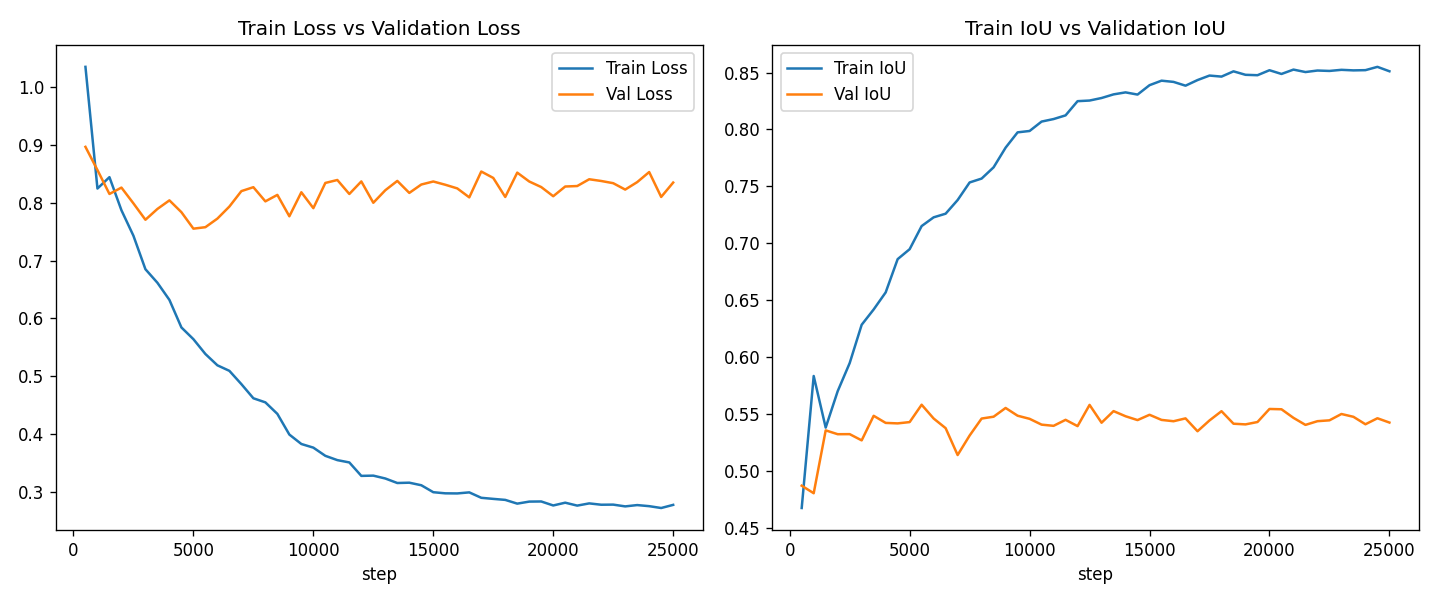



---------------------------------
---------------------------------

FINAL TEST IoU:: 0.5595
FINAL TEST LOSS:: 0.7664

(threshold 0.5, chosen on validation only; at the default 0.5 test IoU is 0.5595)

---------------------------------
---------------------------------


Writing per-image results ...
  wrote 1561 composites and 20 samples

per-lesion-area-quartile test IoU (Q0 = sparsest lesions):
  Q0  n=  372  median area 0.0313  mean per-image IoU 0.3336
  Q1  n=  395  median area 0.0923  mean per-image IoU 0.4698
  Q2  n=  413  median area 0.2027  mean per-image IoU 0.5540
  Q3  n=  381  median area 0.4677  mean per-image IoU 0.6583


Some sample outputs:



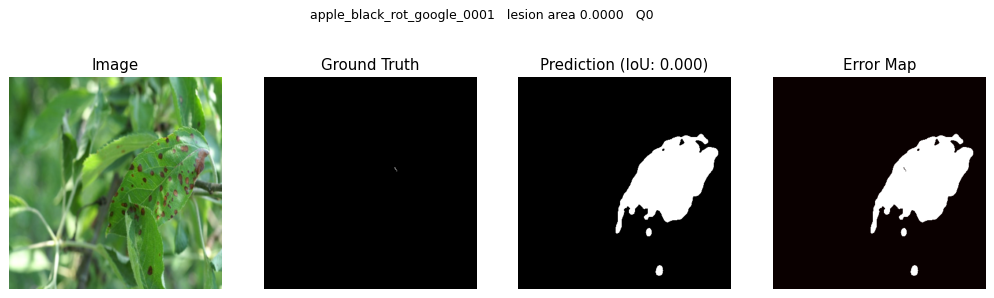

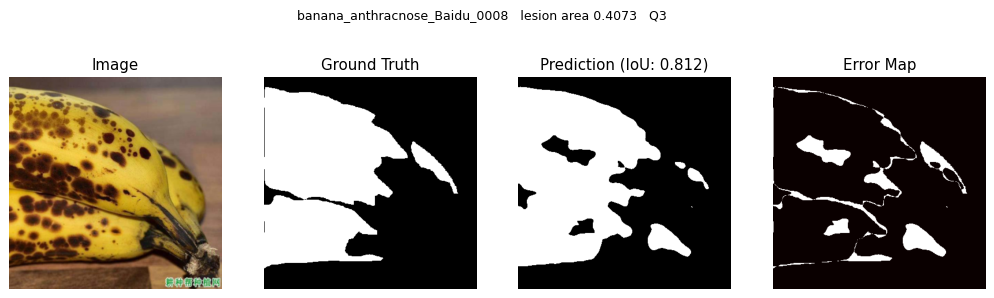

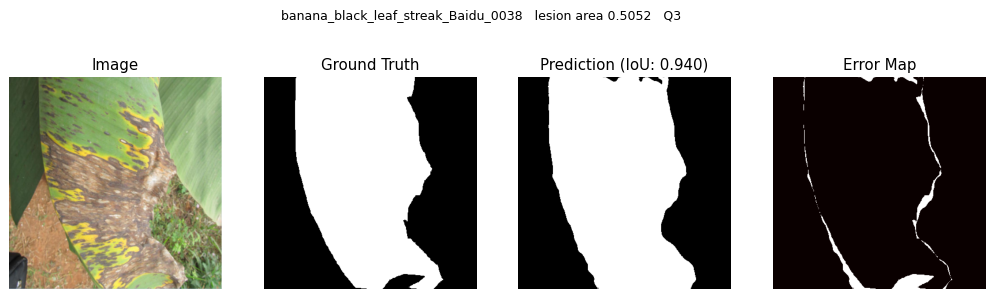

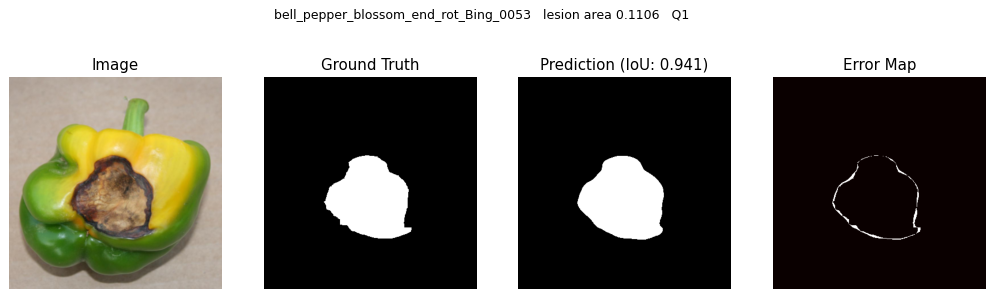

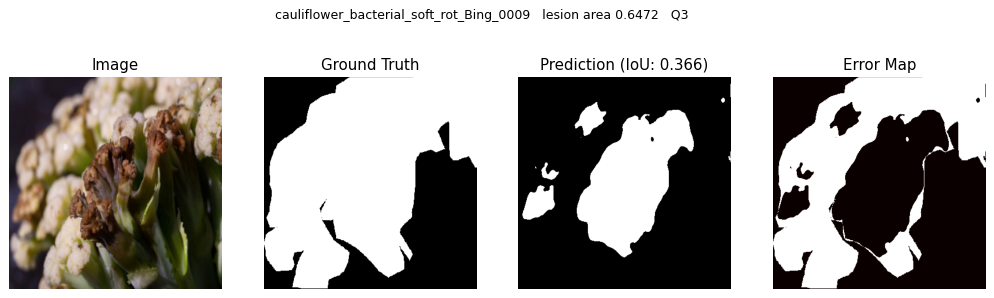

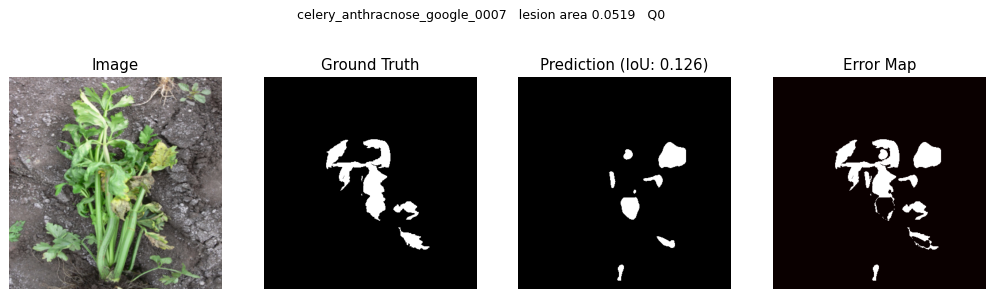

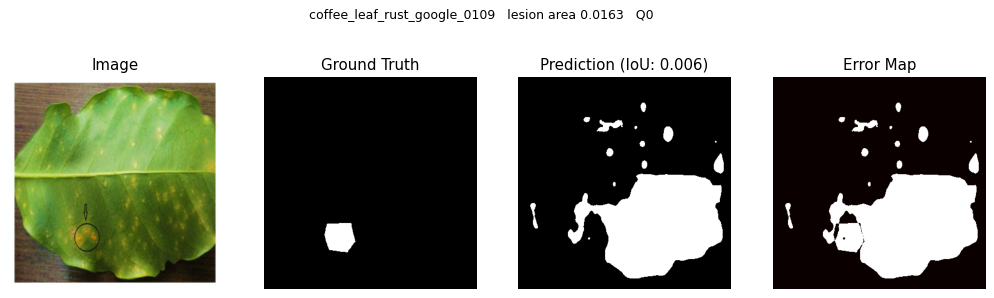

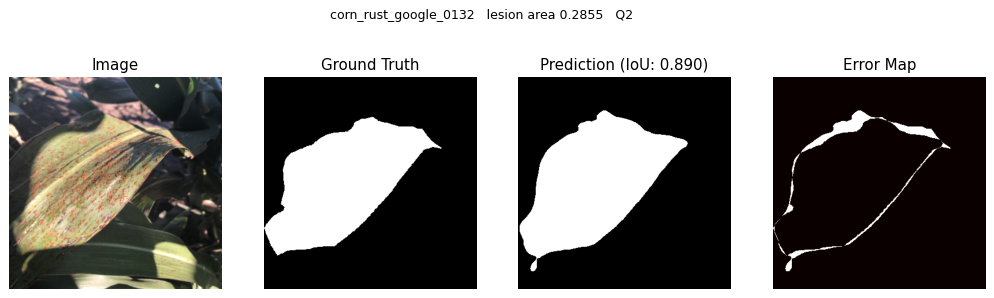

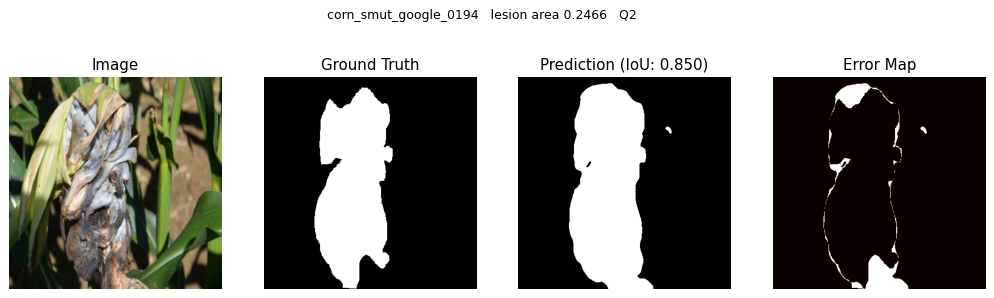

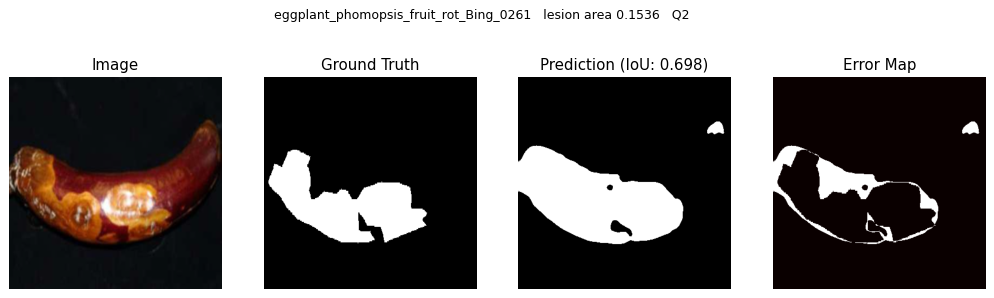

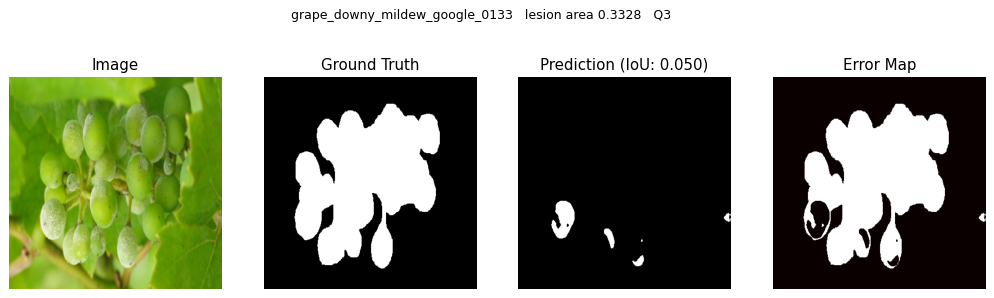

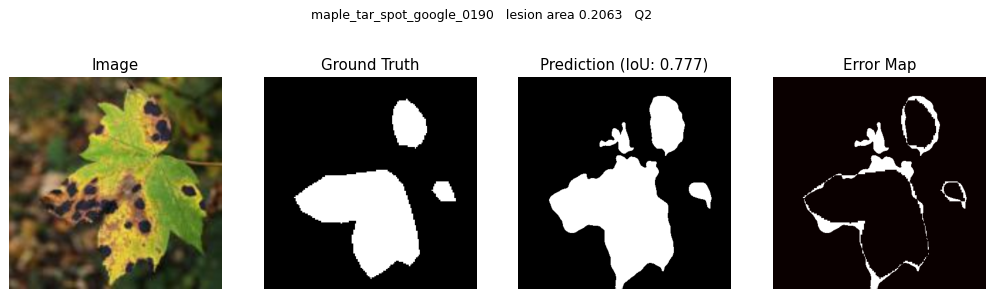

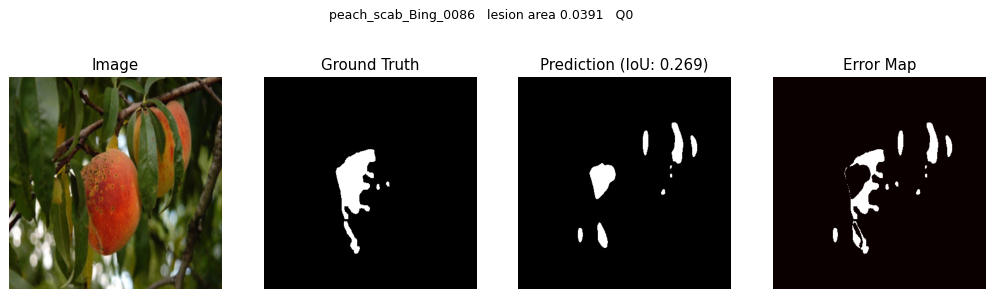

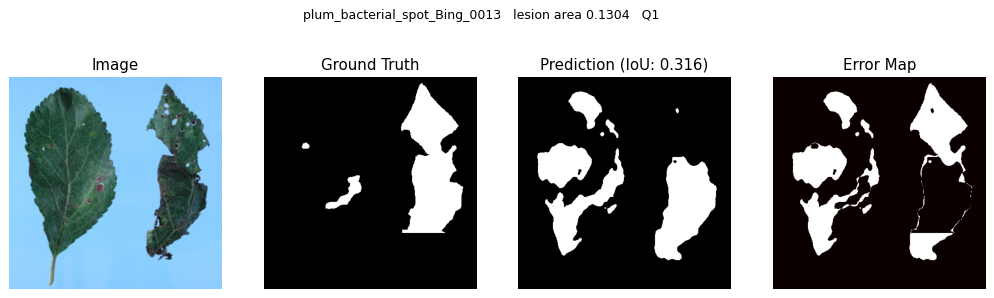

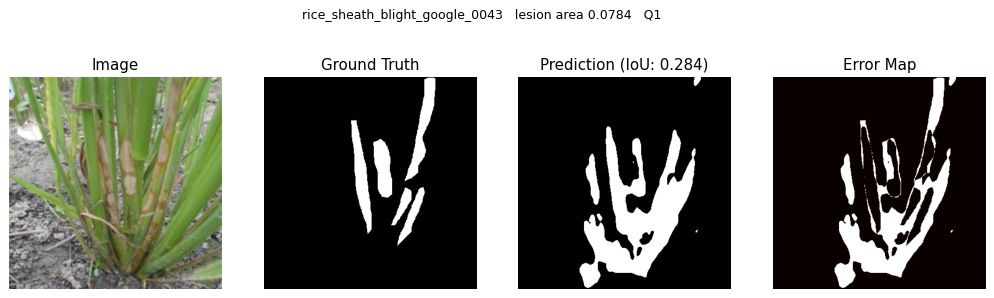

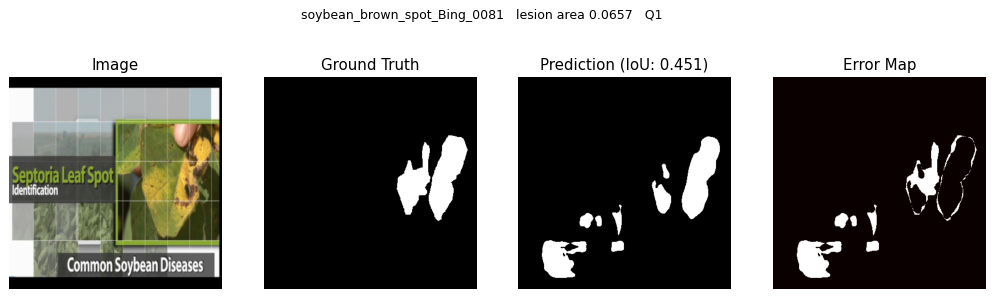

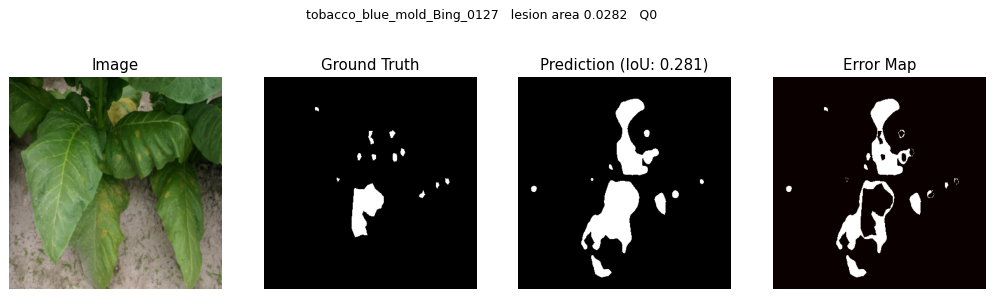

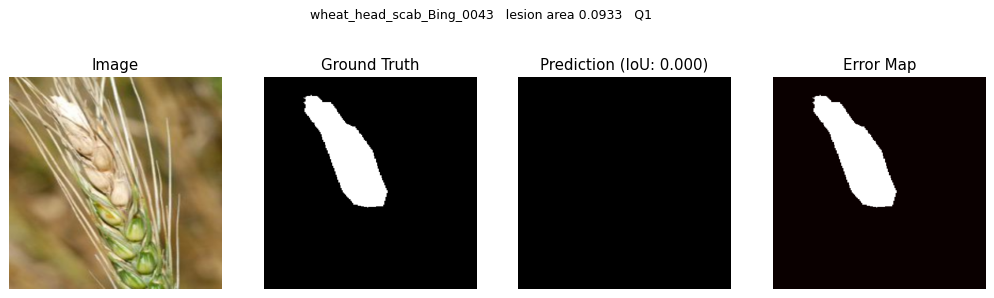

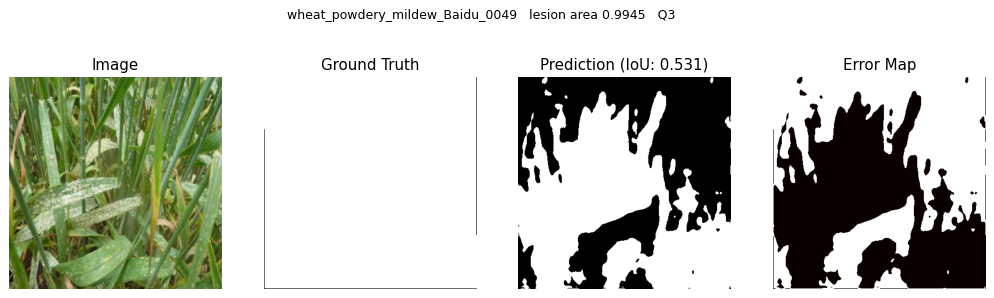

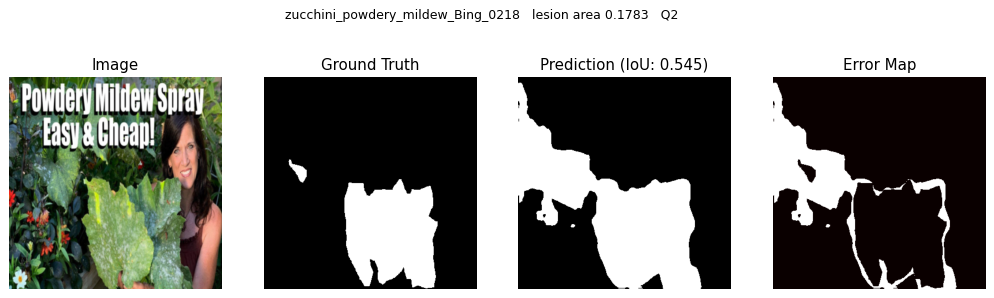


wrote /content/drive/MyDrive/results_plantseg_sup_10pct_384_seed42.zip  (79.3 MB)


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>



>>> Test images saved successfully using BEST model
>>> best val IoU 0.5581 | FINAL TEST IoU 0.5595 @ threshold 0.5
>>> /content/drive/MyDrive/results_plantseg_sup_10pct_384_seed42.zip


In [ ]:
# =====================================================================
#  plantseg_train_sup.py -- supervised baseline on PlantSeg (binary).
#  Fixed STEP budget, resumes after a disconnect.
#  On completion, with the BEST-VALIDATION checkpoint:
#    training curves, final test IoU/loss, per-image CSV,
#    every test image as image|GT|prediction, 20 samples with error maps,
#    packed predictions, all zipped to Drive and downloaded.
#  Model selection and threshold use VALIDATION only.
# =====================================================================
import os, csv, json, math, time, random, shutil, zipfile, collections
import numpy as np
import matplotlib; matplotlib.use("Agg")
import matplotlib.pyplot as plt
from PIL import Image
import torch, torch.nn as nn, torch.optim as optim, torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader
from torchvision import transforms, models
import torchvision.transforms.functional as TF

FRESH           = False     # True wipes this run; leave False so disconnects resume
BUDGET          = "10pct"    # 05pct | 10pct | 20pct | 50pct | 100pct
MAX_STEPS       = 25000
EVAL_EVERY      = 500
CKPT_EVERY      = 2500
LR_PATIENCE     = 5
IMG_SIZE        = 384
BATCH_L         = 4
BATCH_EVAL      = 8
N_SAMPLES       = 20         # shown inline, with error maps
SAVE_ALL_IMAGES = True       # one image|GT|pred jpg per test image (~70 MB)
AUTO_DOWNLOAD   = True
LR_ENCODER, LR_DECODER, WEIGHT_DECAY = 1e-5, 1e-4, 1e-4
FP_DROPOUT      = 0.5        # unused here; keeps the model identical across files
TRAIN_SEED, LABEL_SEED = 42, 42
NUM_WORKERS     = min(4, os.cpu_count() or 2)
THRESHOLDS      = (0.3, 0.4, 0.5, 0.6, 0.7)
BUDGET_N = {"05pct": 268, "10pct": 537, "20pct": 1073, "50pct": 2684, "100pct": 5367}

SAVE, CACHE, DS_DIR = "/content/drive/MyDrive", "/content/cache", "/content/my_images/plantseg"
RUN = f"plantseg_sup_{BUDGET}_{IMG_SIZE}_seed{TRAIN_SEED}"
OUT = f"{SAVE}/runs/{RUN}"                 # Drive: weights + small artefacts
LOC = f"/content/results_{RUN}"            # local: the many image files
if FRESH and os.path.isdir(OUT):
    shutil.rmtree(OUT, ignore_errors=True); print(f"FRESH: removed {OUT}")
os.makedirs(OUT, exist_ok=True)

random.seed(TRAIN_SEED); np.random.seed(TRAIN_SEED)
torch.manual_seed(TRAIN_SEED); torch.cuda.manual_seed_all(TRAIN_SEED)
torch.backends.cudnn.deterministic = True; torch.backends.cudnn.benchmark = False
DEV = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"{RUN}\ndevice {DEV}  {torch.cuda.get_device_name(0) if DEV.type=='cuda' else ''}"
      f"   cpus {os.cpu_count()}  workers {NUM_WORKERS}")

# ------------------- splits / fractions, derived from data -------------
IDX = json.load(open(f"{CACHE}/index.json"))
stems, row_of, split_of = IDX["stems"], IDX["row_of"], IDX["split_of"]
disk = {sp: sorted(s for s in stems if split_of[s] == sp)
        for sp in ("train", "val", "test")}
meta = {os.path.splitext(r["Name"])[0]: r for r in
        csv.DictReader(open(f"{DS_DIR}/Metadata.csv", encoding="utf-8-sig", newline=""))}
frac = {k: float(v["Mask ratio"]) for k, v in meta.items()}
cuts = np.percentile([frac[s] for s in disk["train"]], [25, 50, 75]).tolist()
FROZEN = [0.059468, 0.138448, 0.300831]
if max(abs(a - b) for a, b in zip(cuts, FROZEN)) > 1e-6:
    raise SystemExit(f"quartile cuts {cuts} differ from the frozen {FROZEN}")
print(f"quartile cuts {[round(c,6) for c in cuts]} (match the frozen audit values)")

_mm = {}
def cache():
    if not _mm:
        _mm["i"] = np.load(IDX["img_path"], mmap_mode="r")
        _mm["m"] = np.load(IDX["msk_path"], mmap_mode="r")
    return _mm["i"], _mm["m"]

def quart(s):
    f = frac[s]
    return 0 if f <= cuts[0] else 1 if f <= cuts[1] else 2 if f <= cuts[2] else 3

_rng = np.random.default_rng(LABEL_SEED)
pools = collections.defaultdict(list)
for s in disk["train"]: pools[quart(s)].append(s)
for k in pools: pools[k] = [pools[k][i] for i in _rng.permutation(len(pools[k]))]
_ntr = len(disk["train"]); _tgt = {k: len(v)/_ntr for k, v in pools.items()}
_ptr = {k: 0 for k in pools}; _cnt = {k: 0 for k in pools}; order = []
for i in range(_ntr):
    k = max((k for k in pools if _ptr[k] < len(pools[k])),
            key=lambda k: _tgt[k]*(i+1) - _cnt[k])
    order.append(pools[k][_ptr[k]]); _ptr[k] += 1; _cnt[k] += 1

labelled = sorted(order[:BUDGET_N[BUDGET]])
print(f"labelled {len(labelled)}  val {len(disk['val'])}  test {len(disk['test'])}")
print(f"quartiles in labelled set: "
      f"{[sum(1 for s in labelled if quart(s)==k) for k in range(4)]}")
print(f"{MAX_STEPS} steps x batch {BATCH_L} = {MAX_STEPS*BATCH_L} image views "
      f"= {MAX_STEPS*BATCH_L/len(labelled):.0f} passes over the labelled set")

MEAN = np.array([0.485, 0.456, 0.406]); STD = np.array([0.229, 0.224, 0.225])
NORM = transforms.Normalize(MEAN.tolist(), STD.tolist())

def joint_geometric(img, msk):
    if random.random() < 0.5: img, msk = TF.hflip(img), TF.hflip(msk)
    if random.random() < 0.5: img, msk = TF.vflip(img), TF.vflip(msk)
    k = random.randint(0, 3)
    if k:
        img = img.rotate(90*k, expand=True, resample=Image.BILINEAR)
        msk = msk.rotate(90*k, expand=True, resample=Image.NEAREST)
    return img, msk

def rrc(img, msk, scale=(0.5, 1.0), ratio=(3/4, 4/3)):
    w, h = img.size; area = w*h
    for _ in range(10):
        t = area*random.uniform(*scale)
        ar = math.exp(random.uniform(math.log(ratio[0]), math.log(ratio[1])))
        cw, ch = int(round(math.sqrt(t*ar))), int(round(math.sqrt(t/ar)))
        if cw <= w and ch <= h:
            x, y = random.randint(0, w-cw), random.randint(0, h-ch)
            return img.crop((x, y, x+cw, y+ch)), msk.crop((x, y, x+cw, y+ch))
    return img, msk

def weak(img, msk):
    img, msk = rrc(img, msk); img, msk = joint_geometric(img, msk)
    return img.resize((IMG_SIZE,)*2, Image.BILINEAR), msk.resize((IMG_SIZE,)*2, Image.NEAREST)

to_img = lambda im: NORM(TF.to_tensor(im))
to_msk = lambda mk: torch.from_numpy((np.array(mk) > 0).astype(np.float32)).unsqueeze(0)

class Labelled(Dataset):
    def __init__(s, st): s.st = list(st)
    def __len__(s): return len(s.st)
    def __getitem__(s, i):
        I, M = cache(); r = row_of[s.st[i]]
        img, msk = weak(Image.fromarray(I[r]), Image.fromarray(M[r]))
        return to_img(img), to_msk(msk)

class Eval(Dataset):
    def __init__(s, st): s.st = list(st)
    def __len__(s): return len(s.st)
    def __getitem__(s, i):
        I, M = cache(); r = row_of[s.st[i]]
        return (to_img(Image.fromarray(I[r]).resize((IMG_SIZE,)*2, Image.BILINEAR)),
                to_msk(Image.fromarray(M[r]).resize((IMG_SIZE,)*2, Image.NEAREST)))

def gen(off):
    g = torch.Generator(); g.manual_seed(TRAIN_SEED + off); return g
def seed_worker(_):
    s = torch.initial_seed() % 2**32; np.random.seed(s); random.seed(s)
LK = dict(num_workers=NUM_WORKERS, pin_memory=DEV.type == "cuda",
          worker_init_fn=seed_worker, persistent_workers=NUM_WORKERS > 0)

loader_l    = DataLoader(Labelled(labelled), BATCH_L, shuffle=True, drop_last=True,
                         generator=gen(101), **LK)
val_loader  = DataLoader(Eval(disk["val"]),  BATCH_EVAL, shuffle=False, **LK)
test_loader = DataLoader(Eval(disk["test"]), BATCH_EVAL, shuffle=False, **LK)

def cycle(dl):
    while True:
        for b in dl: yield b

# ------------------------------- model --------------------------------
SPEC = dict(builder=models.resnet50, weights=models.ResNet50_Weights.DEFAULT,
            channels=(64, 256, 512, 1024, 2048), decoder=(512, 256, 128, 64))
class DoubleConv(nn.Module):
    def __init__(s, i, o):
        super().__init__()
        s.net = nn.Sequential(nn.Conv2d(i,o,3,1,1,bias=False), nn.BatchNorm2d(o), nn.ReLU(True),
                              nn.Conv2d(o,o,3,1,1,bias=False), nn.BatchNorm2d(o), nn.ReLU(True))
    def forward(s, x): return s.net(x)
class Up(nn.Module):
    def __init__(s, i, k, o):
        super().__init__(); s.reduce = nn.Conv2d(i, i//2, 1, bias=False); s.conv = DoubleConv(i//2+k, o)
    def forward(s, x, skip):
        x = F.interpolate(x, size=skip.shape[-2:], mode="bilinear", align_corners=False)
        return s.conv(torch.cat([s.reduce(x), skip], 1))
class ResUNet(nn.Module):
    def __init__(s):
        super().__init__()
        base = SPEC["builder"](weights=SPEC["weights"])
        c0,c1,c2,c3,c4 = SPEC["channels"]; d1,d2,d3,d4 = SPEC["decoder"]
        L = list(base.children())
        s.stem = nn.Sequential(*L[:3]); s.pool = L[3]
        s.l1,s.l2,s.l3,s.l4 = L[4],L[5],L[6],L[7]
        s.u1,s.u2,s.u3,s.u4 = Up(c4,c3,d1), Up(d1,c2,d2), Up(d2,c1,d3), Up(d3,c0,d4)
        s.head = nn.Sequential(nn.Conv2d(d4,32,3,padding=1,bias=False),
                               nn.BatchNorm2d(32), nn.ReLU(True), nn.Conv2d(32,1,1))
    def enc_params(s):
        for m in (s.stem, s.l1, s.l2, s.l3, s.l4): yield from m.parameters()
    def dec_params(s):
        for m in (s.u1, s.u2, s.u3, s.u4, s.head): yield from m.parameters()
    def encode(s, x):
        x0 = s.stem(x); x1 = s.l1(s.pool(x0)); x2 = s.l2(x1); x3 = s.l3(x2)
        return [x0, x1, x2, x3, s.l4(x3)]
    def decode(s, f, size):
        d = s.u1(f[4], f[3]); d = s.u2(d, f[2]); d = s.u3(d, f[1]); d = s.u4(d, f[0])
        return s.head(F.interpolate(d, size=size, mode="bilinear", align_corners=False))
    def forward(s, x, need_fp=False):
        size = x.shape[-2:]; f = s.encode(x)
        if need_fp:
            p = [F.dropout2d(t, p=FP_DROPOUT, training=s.training) for t in f]
            return s.decode([torch.cat((a,b)) for a,b in zip(f,p)], size).chunk(2)
        return s.decode(f, size)

bce_none = nn.BCEWithLogitsLoss(reduction="none")
def tversky(logits, tgt, eps=1.0):
    p = torch.sigmoid(logits)
    tp = (p*tgt).sum((1,2,3)); fp = (p*(1-tgt)).sum((1,2,3)); fn = ((1-p)*tgt).sum((1,2,3))
    return 1 - (tp+eps)/(tp+0.5*fp+0.5*fn+eps)
def sup_loss(logits, tgt):
    return bce_none(logits, tgt).mean((1,2,3)) + tversky(logits, tgt)

@torch.no_grad()
def evaluate(net, loader, ths=THRESHOLDS):
    net.eval()
    inter = {t: 0.0 for t in ths}; union = {t: 0.0 for t in ths}
    tp2 = {t: 0.0 for t in ths}; tot = {t: 0.0 for t in ths}
    ls, nb = 0.0, 0
    for x, y in loader:
        x, y = x.to(DEV, non_blocking=True), y.to(DEV, non_blocking=True)
        with torch.amp.autocast("cuda"):
            logits = net(x)
        logits = logits.float()
        ls += sup_loss(logits, y).mean().item(); nb += 1
        prob = torch.sigmoid(logits)
        for t in ths:
            pr = (prob > t).float()
            i = (pr*y).sum((1,2,3)); u = pr.sum((1,2,3)) + y.sum((1,2,3)) - i
            inter[t] += i.sum().item(); union[t] += u.sum().item()
            tp2[t] += 2*i.sum().item(); tot[t] += (pr.sum((1,2,3))+y.sum((1,2,3))).sum().item()
    out = {str(t): dict(iou=inter[t]/max(union[t],1e-6), dice=tp2[t]/max(tot[t],1e-6))
           for t in ths}
    out["loss"] = ls/max(nb, 1)
    return out

# ------------------------- resume or start fresh ----------------------
model = ResUNet().to(DEV)
opt = optim.AdamW([{"params": list(model.enc_params()), "lr": LR_ENCODER},
                   {"params": list(model.dec_params()), "lr": LR_DECODER}],
                  weight_decay=WEIGHT_DECAY)
sched = optim.lr_scheduler.ReduceLROnPlateau(opt, mode="max", patience=LR_PATIENCE, factor=0.5)
scaler = torch.amp.GradScaler("cuda")
step, best, history = 0, -1.0, []
CK, BEST = f"{OUT}/ckpt.pt", f"{OUT}/best.pt"

if os.path.exists(CK):
    c = torch.load(CK, map_location=DEV, weights_only=False)
    model.load_state_dict(c["model"]); opt.load_state_dict(c["opt"])
    if "sched" in c:  sched.load_state_dict(c["sched"])
    if "scaler" in c: scaler.load_state_dict(c["scaler"])
    step, best, history = c["step"], c["best"], c["history"]
    print(f"RESUMED from step {step}  (best val IoU so far {best:.4f})")
else:
    print("starting fresh")
# NOTE: dataloader worker RNG is not restored on resume, so a resumed run is
# reproducible from its last checkpoint, not bit-for-bit from step 0.

def save_ckpt():
    torch.save(dict(model=model.state_dict(), opt=opt.state_dict(),
                    sched=sched.state_dict(), scaler=scaler.state_dict(),
                    step=step, best=best, history=history), CK)
    json.dump(dict(run=RUN, method="sup", budget=BUDGET, img=IMG_SIZE,
                   seed=TRAIN_SEED, max_steps=MAX_STEPS, batch=BATCH_L,
                   n_labelled=len(labelled), history=history),
              open(f"{OUT}/history.json", "w"), indent=1)

# -------------------------------- train -------------------------------
it_l = cycle(loader_l)
print("=" * 70)
print(f"SUPERVISED  --  {len(labelled)} labelled images, {MAX_STEPS} steps")
print("=" * 70)
t0, t_last = time.time(), time.time()
run_loss, run_i, run_u, run_n = 0.0, 0.0, 0.0, 0

while step < MAX_STEPS:
    model.train()
    img_x, msk_x = next(it_l)
    img_x = img_x.to(DEV, non_blocking=True); msk_x = msk_x.to(DEV, non_blocking=True)
    opt.zero_grad(set_to_none=True)
    with torch.amp.autocast("cuda"):
        seg = model(img_x)
        loss = sup_loss(seg.float(), msk_x).mean()
    scaler.scale(loss).backward(); scaler.step(opt); scaler.update()
    step += 1

    run_loss += loss.item(); run_n += 1
    with torch.no_grad():
        pr = (torch.sigmoid(seg.float()) > 0.5).float()
        i = (pr*msk_x).sum(); run_i += i.item()
        run_u += (pr.sum() + msk_x.sum() - i).item()

    if step % EVAL_EVERY == 0:
        train_loss, train_iou = run_loss/run_n, run_i/max(run_u, 1e-6)
        run_loss, run_i, run_u, run_n = 0.0, 0.0, 0.0, 0
        m = evaluate(model, val_loader); val_iou = m["0.5"]["iou"]
        prev_lr = opt.param_groups[-1]["lr"]; sched.step(val_iou)
        cur_lr = opt.param_groups[-1]["lr"]
        lr_note = f"   [decoder LR {prev_lr:.2e} -> {cur_lr:.2e}]" if cur_lr != prev_lr else ""
        saved = ""
        if val_iou > best:
            best = val_iou; torch.save(model.state_dict(), BEST); saved = "   <-- saved"
        history.append(dict(step=step, train_loss=train_loss, train_iou=train_iou,
                            val_loss=m["loss"], val_iou=val_iou, val=m, lr=cur_lr,
                            minutes=round((time.time()-t0)/60, 1)))
        sps = EVAL_EVERY/(time.time()-t_last); t_last = time.time()
        print(f"step {step:6d} | train loss {train_loss:.4f} | train IoU {train_iou:.4f} | "
              f"val loss {m['loss']:.4f} | val IoU {val_iou:.4f} | best {best:.4f} | "
              f"{sps:.2f} it/s | ETA {(MAX_STEPS-step)/sps/3600:.1f}h{saved}{lr_note}")
        json.dump(dict(run=RUN, history=history), open(f"{OUT}/history.json", "w"), indent=1)

    if step % CKPT_EVERY == 0:
        save_ckpt(); print(f"    checkpointed at step {step}")

save_ckpt()
print(f"\ntraining done: {MAX_STEPS} steps in {(time.time()-t0)/3600:.2f}h   "
      f"best val IoU {best:.4f}")

# --------------------------- training curves --------------------------
from IPython.display import Image as IPImage, display
xs = [h["step"] for h in history]
plt.figure(figsize=(12, 5))
plt.subplot(1, 2, 1)
plt.plot(xs, [h["train_loss"] for h in history], label="Train Loss")
plt.plot(xs, [h.get("val_loss", np.nan) for h in history], label="Val Loss")
plt.xlabel("step"); plt.legend(); plt.title("Train Loss vs Validation Loss")
plt.subplot(1, 2, 2)
plt.plot(xs, [h["train_iou"] for h in history], label="Train IoU")
plt.plot(xs, [h.get("val_iou", h.get("val", {}).get("0.5", {}).get("iou", np.nan))
              for h in history], label="Val IoU")
plt.xlabel("step"); plt.legend(); plt.title("Train IoU vs Validation IoU")
plt.tight_layout(); plt.savefig(f"{OUT}/training_curves.png", dpi=120); plt.close()
display(IPImage(filename=f"{OUT}/training_curves.png"))

# ================ FINAL EVALUATION with the BEST model ================
net = ResUNet().to(DEV); net.load_state_dict(torch.load(BEST, map_location=DEV)); net.eval()
val_m = evaluate(net, val_loader)
tuned = max(THRESHOLDS, key=lambda t: val_m[str(t)]["iou"])
test_m = evaluate(net, test_loader)

print("\n\n---------------------------------")
print("---------------------------------")
print(f"\nFINAL TEST IoU:: {test_m[str(tuned)]['iou']:.4f}")
print(f"FINAL TEST LOSS:: {test_m['loss']:.4f}")
print(f"\n(threshold {tuned}, chosen on validation only; "
      f"at the default 0.5 test IoU is {test_m['0.5']['iou']:.4f})")
print("\n---------------------------------")
print("---------------------------------\n\n")

shutil.rmtree(LOC, ignore_errors=True)
os.makedirs(f"{LOC}/all_test_results", exist_ok=True)
os.makedirs(f"{LOC}/sample_outputs", exist_ok=True)

order_t = sorted(disk["test"], key=lambda s: frac[s])        # rule fixed in advance
sample_set = {order_t[int(k*(len(order_t)-1)/(N_SAMPLES-1))]: k for k in range(N_SAMPLES)}

rows = []
preds = np.zeros((len(disk["test"]), IMG_SIZE, IMG_SIZE), dtype=bool)
shown = []
pos = 0
print("Writing per-image results ...")
with torch.no_grad():
    for x, y in test_loader:
        x, y = x.to(DEV, non_blocking=True), y.to(DEV, non_blocking=True)
        with torch.amp.autocast("cuda"):
            prob = torch.sigmoid(net(x).float())
        for b in range(x.size(0)):
            s = disk["test"][pos]
            g = y[b, 0]
            r = dict(stem=s, disease=meta[s]["Disease"], plant=meta[s]["Plant"],
                     gt_frac=round(frac[s], 6), quartile=quart(s))
            for t in THRESHOLDS:
                p_t = (prob[b, 0] > t).float()
                i = (p_t*g).sum().item(); u = (p_t.sum() + g.sum()).item() - i
                r[f"iou@{t}"]  = round(i/max(u, 1e-6), 6)
                r[f"dice@{t}"] = round(2*i/max(p_t.sum().item()+g.sum().item(), 1e-6), 6)
                if t == 0.5: r["pred_frac"] = round(p_t.mean().item(), 6)
            rows.append(r)

            pr = (prob[b, 0] > tuned).cpu().numpy()
            preds[pos] = pr
            gt = g.cpu().numpy() > 0.5
            img = np.clip(x[b].cpu().permute(1,2,0).numpy()*STD + MEAN, 0, 1)
            img8 = (img*255).astype(np.uint8)

            if SAVE_ALL_IMAGES:                         # PIL composite: fast
                w = IMG_SIZE
                sheet = Image.new("RGB", (w*3, w))
                sheet.paste(Image.fromarray(img8), (0, 0))
                sheet.paste(Image.fromarray((gt*255).astype(np.uint8)).convert("RGB"), (w, 0))
                sheet.paste(Image.fromarray((pr*255).astype(np.uint8)).convert("RGB"), (w*2, 0))
                sheet.save(f"{LOC}/all_test_results/{s}.jpg", quality=85)

            if s in sample_set:
                k = sample_set[s]
                err = np.abs(gt.astype(float) - pr.astype(float))
                fig, ax = plt.subplots(1, 4, figsize=(14, 4))
                ax[0].imshow(img);                        ax[0].set_title("Image")
                ax[1].imshow(gt, cmap="gray");            ax[1].set_title("Ground Truth")
                ax[2].imshow(pr, cmap="gray")
                ax[2].set_title(f"Prediction (IoU: {r[f'iou@{tuned}']:.3f})")
                ax[3].imshow(err, cmap="hot");            ax[3].set_title("Error Map")
                for a in ax: a.axis("off")
                fig.suptitle(f"{s}   lesion area {frac[s]:.4f}   Q{quart(s)}", fontsize=10)
                fp = f"{LOC}/sample_outputs/{k:02d}_{s}.png"
                plt.savefig(fp, dpi=90, bbox_inches="tight"); plt.close(fig)
                shown.append(fp)
            pos += 1
print(f"  wrote {pos} composites and {len(shown)} samples")

byq = {}
print("\nper-lesion-area-quartile test IoU (Q0 = sparsest lesions):")
for q in range(4):
    sub = [r for r in rows if r["quartile"] == q]
    byq[q] = dict(n=len(sub),
                  mean_iou=round(float(np.mean([r[f"iou@{tuned}"] for r in sub])), 4),
                  median_gt_frac=round(float(np.median([r["gt_frac"] for r in sub])), 4))
    print(f"  Q{q}  n={byq[q]['n']:5d}  median area {byq[q]['median_gt_frac']:.4f}  "
          f"mean per-image IoU {byq[q]['mean_iou']:.4f}")

with open(f"{LOC}/test_per_image.csv", "w", newline="") as fh:
    w = csv.DictWriter(fh, fieldnames=list(rows[0].keys())); w.writeheader(); w.writerows(rows)
json.dump(dict(run=RUN, method="sup", budget=BUDGET, seed=TRAIN_SEED,
               n_labelled=len(labelled), max_steps=MAX_STEPS, img=IMG_SIZE,
               best_val_iou=best, tuned_threshold=tuned,
               val=val_m, test=test_m, test_by_quartile=byq),
          open(f"{LOC}/test_summary.json", "w"), indent=1)
np.save(f"{LOC}/test_pred_packed.npy", np.packbits(preds, axis=-1))
json.dump(dict(order=disk["test"], threshold=tuned, img_size=IMG_SIZE,
               unpack="np.unpackbits(a, axis=-1, count=IMG_SIZE).astype(bool)"),
          open(f"{LOC}/test_pred_index.json", "w"))
shutil.copy(f"{OUT}/history.json", f"{LOC}/history.json")
shutil.copy(f"{OUT}/training_curves.png", f"{LOC}/training_curves.png")
shutil.copy(f"{LOC}/test_summary.json", f"{OUT}/test_summary.json")
shutil.copy(f"{LOC}/test_per_image.csv", f"{OUT}/test_per_image.csv")

print("\n\nSome sample outputs:\n")
for fp in shown:
    display(IPImage(filename=fp))

# ------------------------------ zip + download ------------------------
ZIPP = f"{SAVE}/results_{RUN}.zip"
with zipfile.ZipFile(ZIPP, "w", zipfile.ZIP_DEFLATED) as z:
    for root, _, fs in os.walk(LOC):
        for f in fs:
            p = os.path.join(root, f)
            z.write(p, arcname=os.path.join(RUN, os.path.relpath(p, LOC)))
print(f"\nwrote {ZIPP}  ({os.path.getsize(ZIPP)/1e6:.1f} MB)")

if AUTO_DOWNLOAD:
    try:
        from google.colab import files
        files.download(ZIPP)
    except Exception as e:
        print(f"(browser download unavailable: {type(e).__name__}. "
              f"The zip is on Drive -- grab it from there.)")

print("\n\n>>> Test images saved successfully using BEST model")
print(f">>> best val IoU {best:.4f} | FINAL TEST IoU {test_m[str(tuned)]['iou']:.4f} "
      f"@ threshold {tuned}")
print(f">>> {ZIPP}")

plantseg_unimatch_10pct_384_seed42
device cuda  Tesla T4   cpus 2  workers 2
quartile cuts [0.059468, 0.138448, 0.300831] (match the frozen audit values)
labelled 537  unlabelled 4830  val 846  test 1561
quartiles in labelled set: [135, 134, 134, 134]
25000 steps: 186 passes over labelled, 20.7 over unlabelled
RESUMED from step 17500  (best val IoU so far 0.5917)
UNIMATCH  --  537 labelled + 4830 unlabelled, 25000 steps, tau=0.95
step  18000 | loss x 0.2138 u 0.0807 | train IoU 0.8835 | val loss 0.8015 | val IoU 0.5879 | best 0.5917 | mask 0.857 | 1.20 it/s | ETA 1.6h
step  18500 | loss x 0.2055 u 0.0820 | train IoU 0.8888 | val loss 0.7879 | val IoU 0.5914 | best 0.5917 | mask 0.857 | 1.19 it/s | ETA 1.5h   [decoder LR 2.50e-05 -> 1.25e-05]
step  19000 | loss x 0.1979 u 0.0768 | train IoU 0.8921 | val loss 0.8004 | val IoU 0.5871 | best 0.5917 | mask 0.861 | 1.19 it/s | ETA 1.4h
step  19500 | loss x 0.1968 u 0.0777 | train IoU 0.8943 | val loss 0.7944 | val IoU 0.5946 | best 0.5946 | 

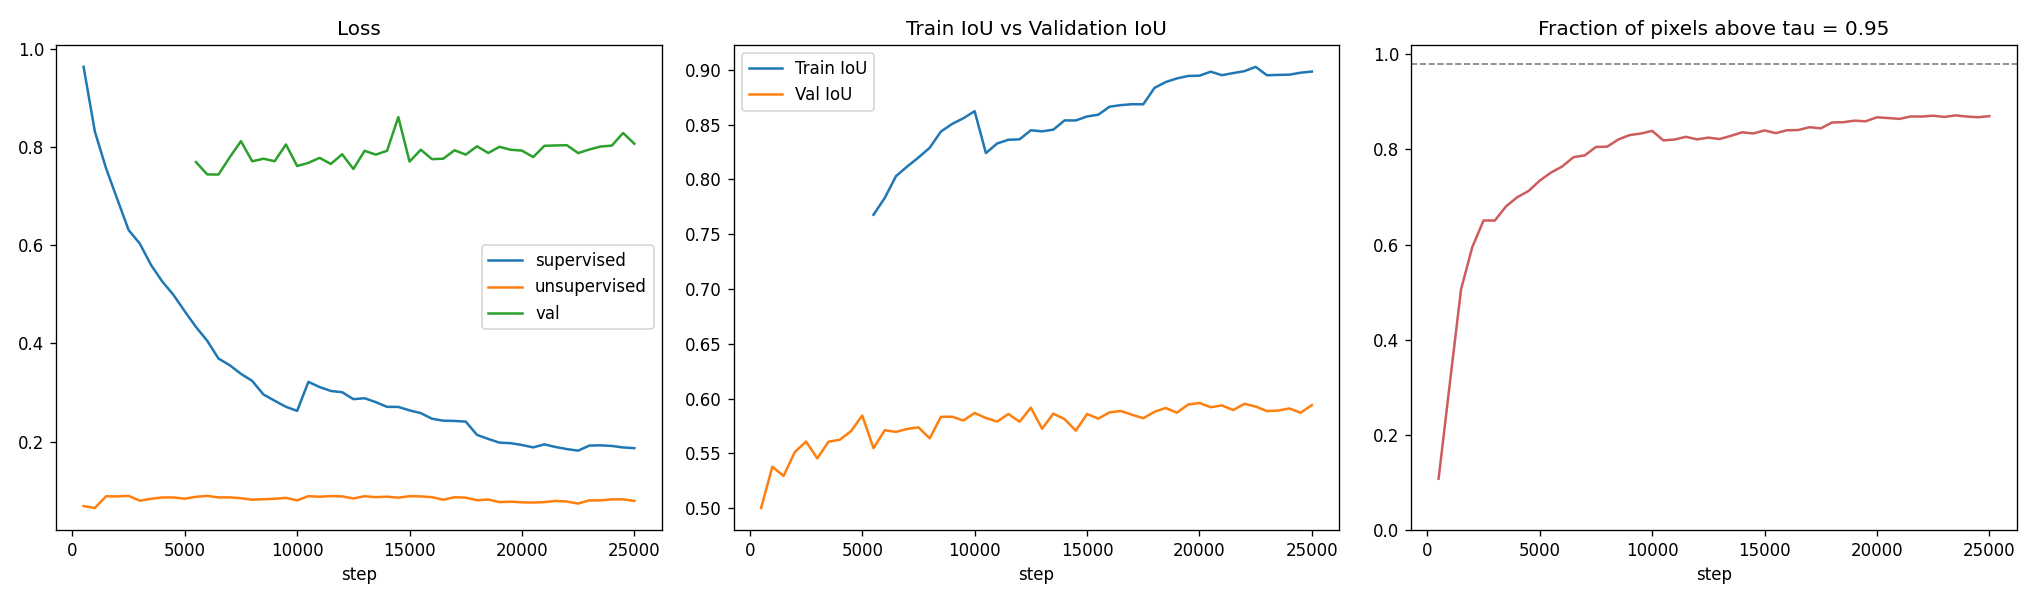



---------------------------------
---------------------------------

FINAL TEST IoU:: 0.5963
FINAL TEST LOSS:: 0.7905

(threshold 0.5, chosen on validation only; at the default 0.5 test IoU is 0.5963)

---------------------------------
---------------------------------


Writing per-image results ...
  wrote 1561 composites and 20 samples

per-lesion-area-quartile test IoU (Q0 = sparsest lesions):
  Q0  n=  372  median area 0.0313  mean per-image IoU 0.3785
  Q1  n=  395  median area 0.0923  mean per-image IoU 0.5111
  Q2  n=  413  median area 0.2027  mean per-image IoU 0.6216
  Q3  n=  381  median area 0.4677  mean per-image IoU 0.6951


Some sample outputs:



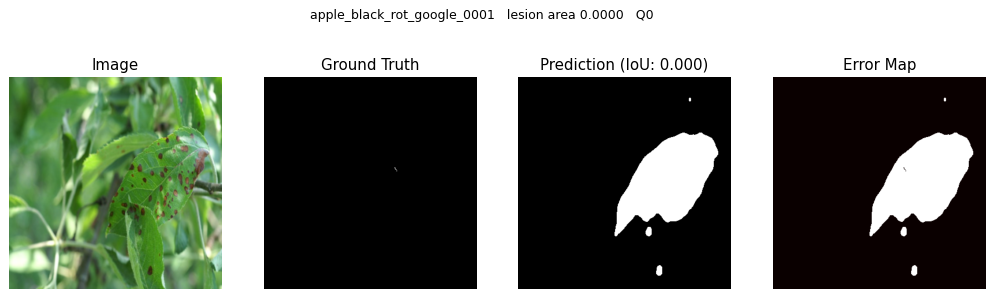

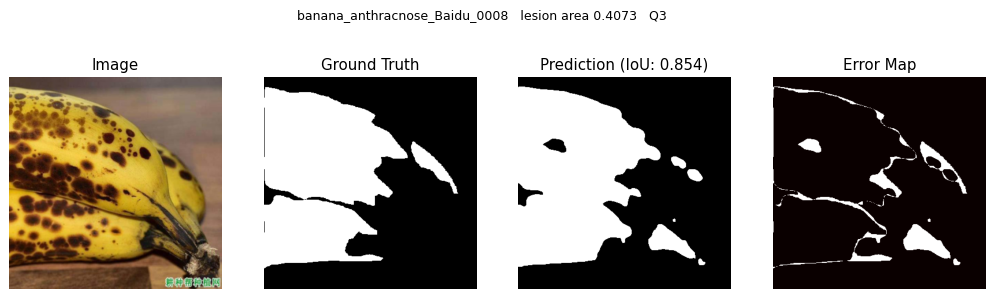

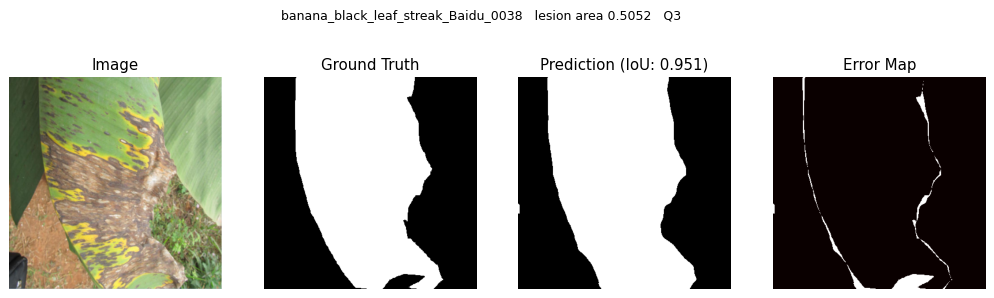

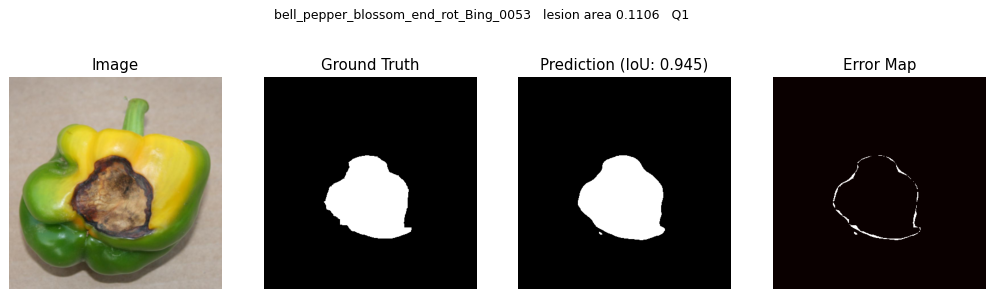

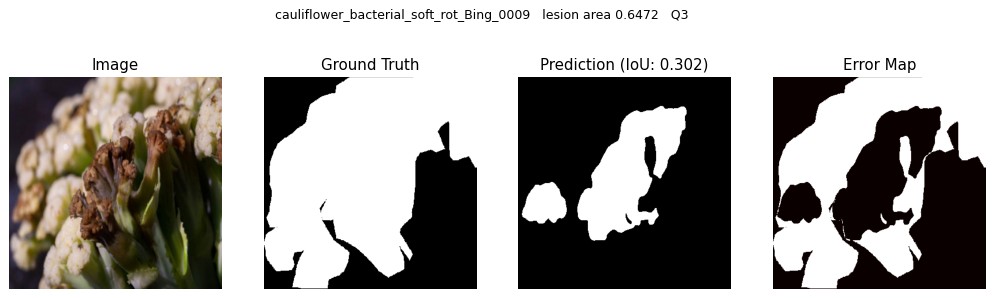

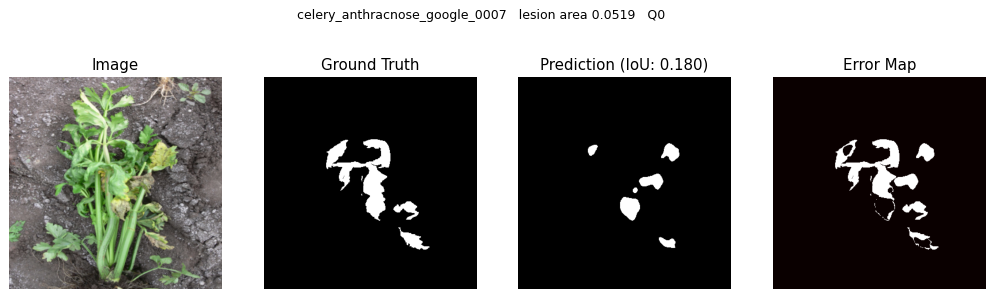

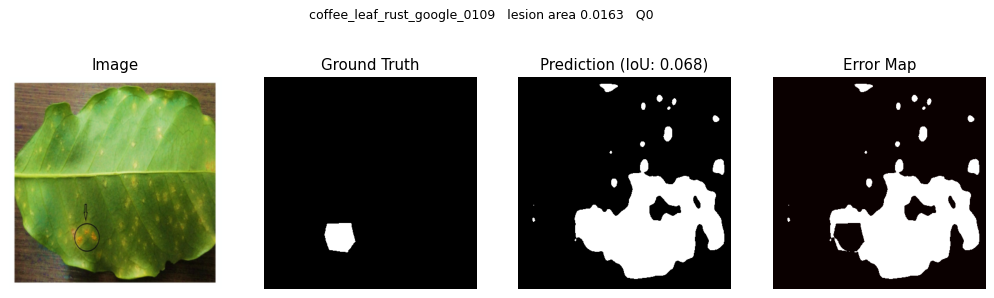

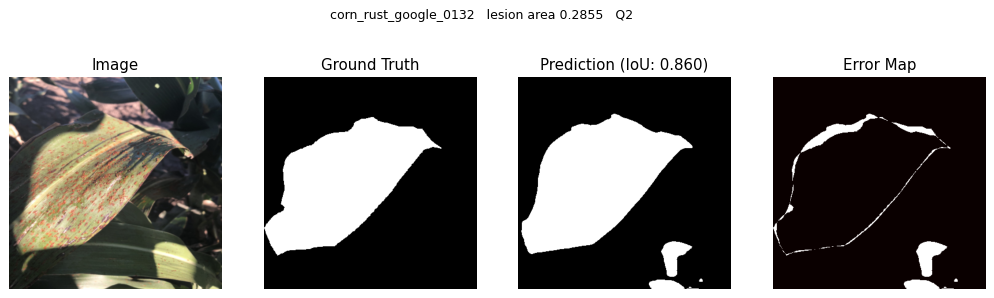

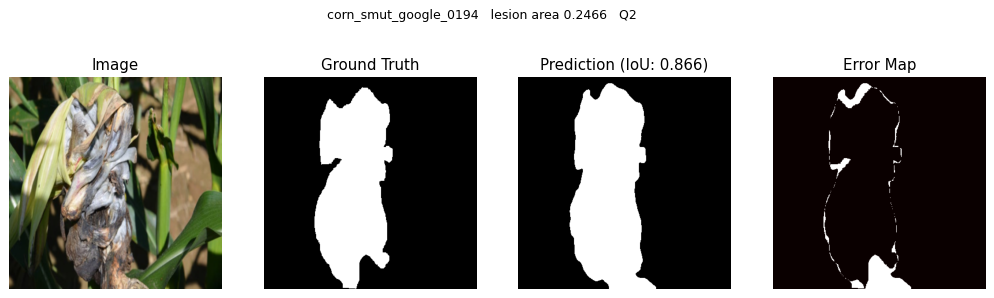

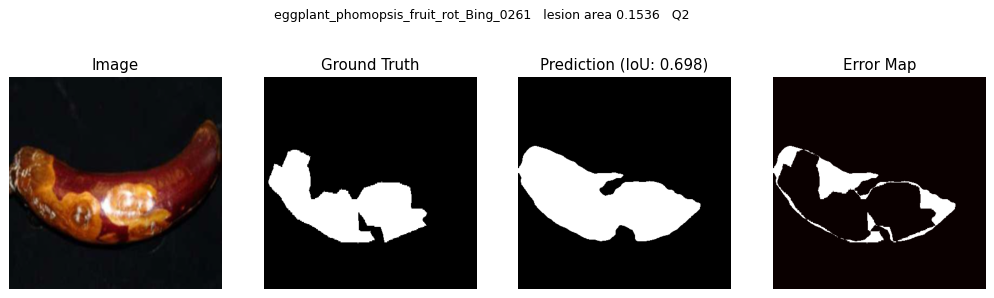

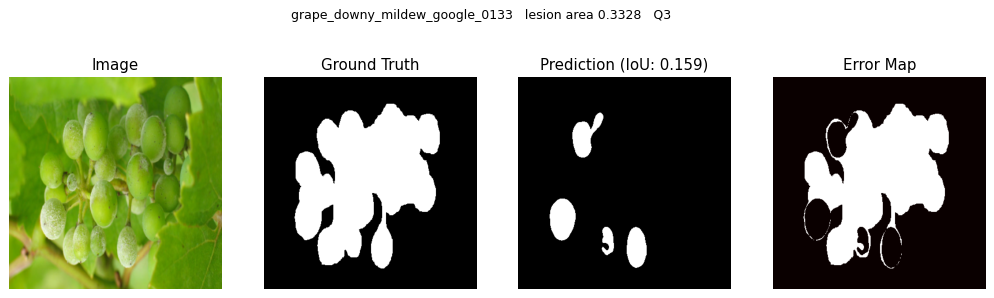

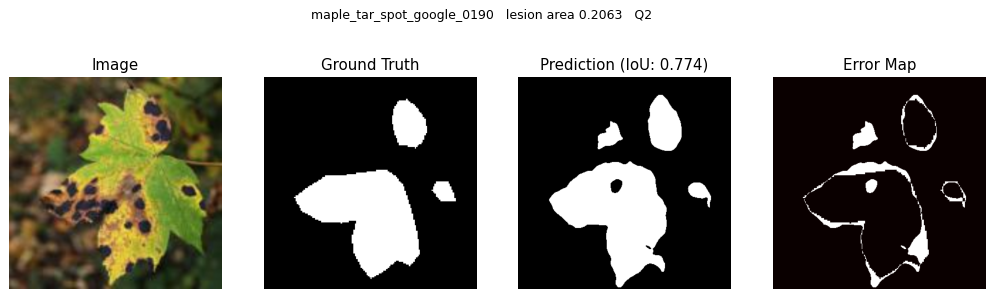

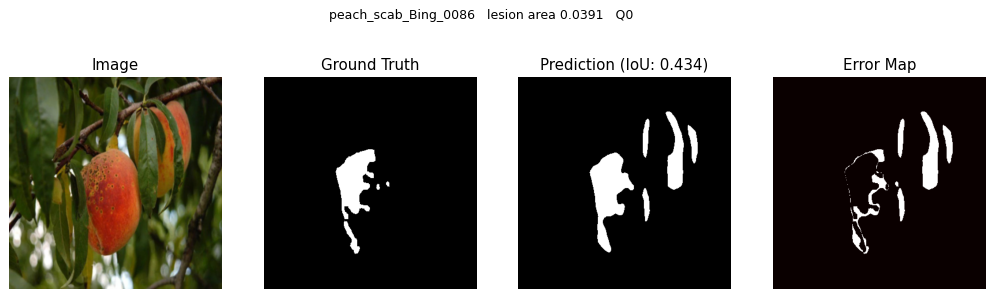

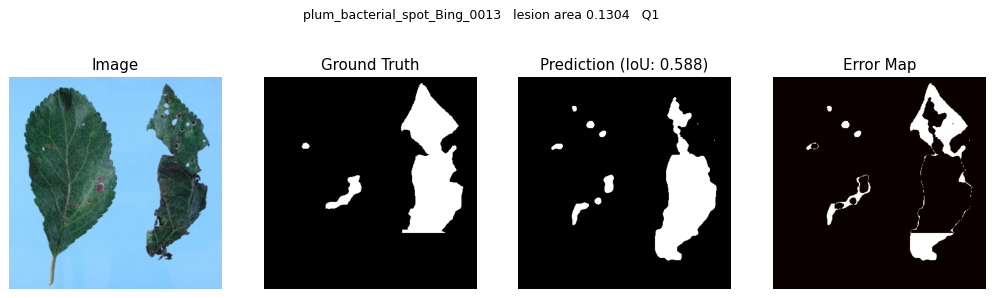

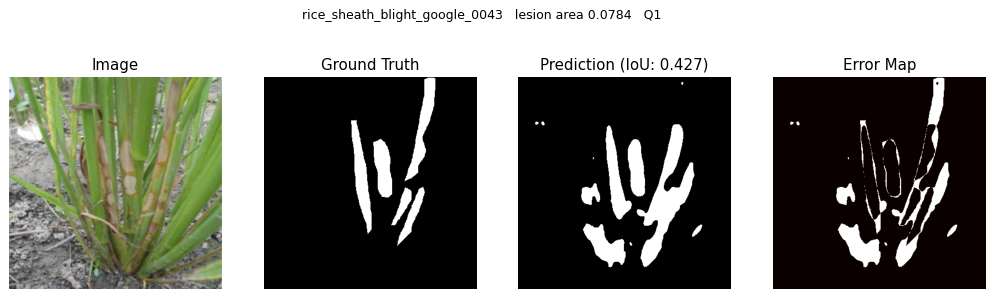

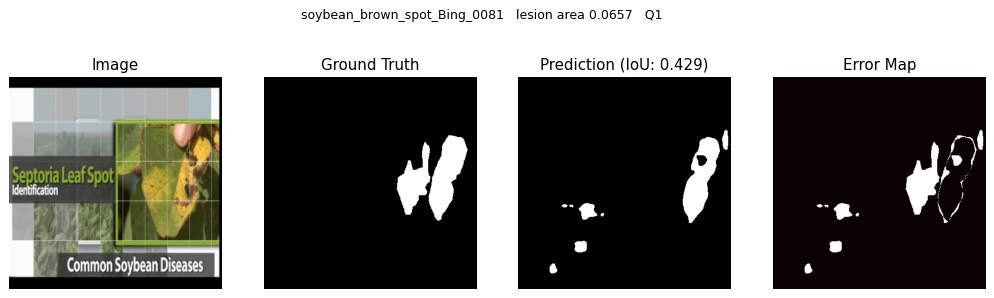

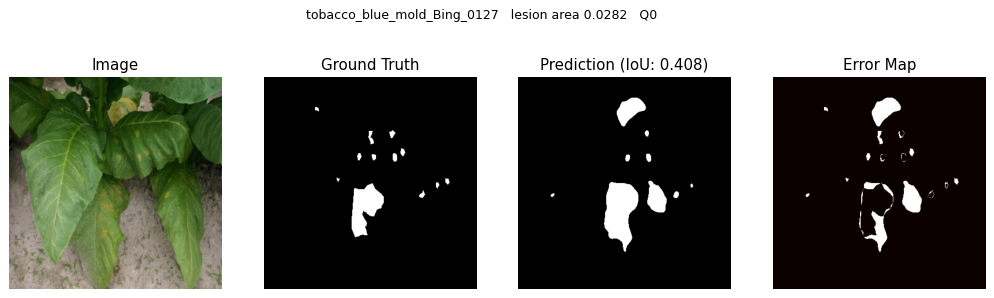

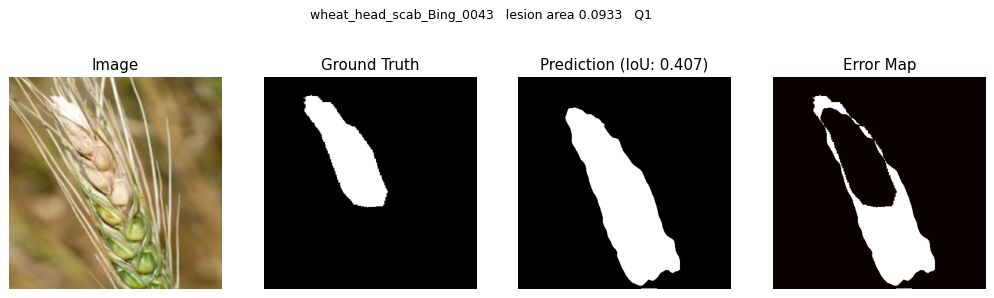

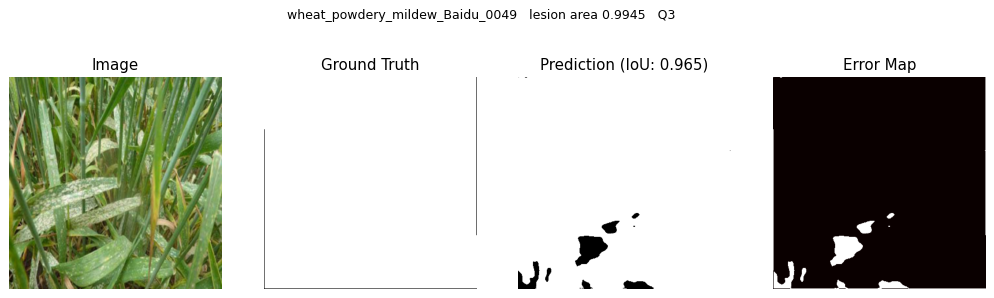

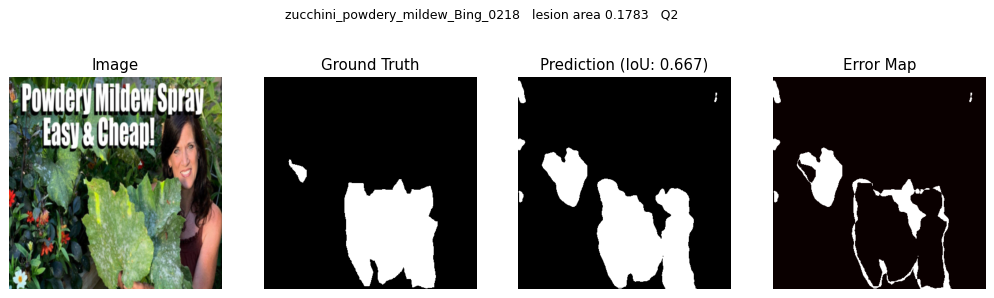


wrote /content/drive/MyDrive/results_plantseg_unimatch_10pct_384_seed42.zip  (79.6 MB)


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>



>>> Test images saved successfully using BEST model
>>> best val IoU 0.5960 | FINAL TEST IoU 0.5963 @ threshold 0.5
>>> /content/drive/MyDrive/results_plantseg_unimatch_10pct_384_seed42.zip


In [ ]:
# =====================================================================
#  plantseg_train_unimatch.py -- UniMatch on PlantSeg (binary).
#  Weak-to-strong consistency: dual strong views + feature perturbation
#  + CutMix, with a confidence threshold on the pseudo-labels.
#  Fixed STEP budget, resumes after a disconnect.
#  On completion, with the BEST-VALIDATION checkpoint:
#    training curves, final test IoU/loss, per-image CSV,
#    every test image as image|GT|prediction, 20 samples with error maps,
#    packed predictions, all zipped to Drive and downloaded.
#  Model selection and threshold use VALIDATION only.
#  Everything above "train" is identical to plantseg_train_sup.py.
# =====================================================================
import os, csv, json, math, time, random, shutil, zipfile, collections
import numpy as np
import matplotlib; matplotlib.use("Agg")
import matplotlib.pyplot as plt
from PIL import Image, ImageFilter
import torch, torch.nn as nn, torch.optim as optim, torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader
from torchvision import transforms, models
import torchvision.transforms.functional as TF

FRESH           = False      # True wipes this run; leave False so disconnects resume
BUDGET          = "10pct"    # 05pct | 10pct | 20pct | 50pct
MAX_STEPS       = 25000
EVAL_EVERY      = 500
CKPT_EVERY      = 2500
LR_PATIENCE     = 5
IMG_SIZE        = 384
BATCH_L         = 4
BATCH_U         = 4
BATCH_EVAL      = 8
N_SAMPLES       = 20
SAVE_ALL_IMAGES = True
AUTO_DOWNLOAD   = True
LR_ENCODER, LR_DECODER, WEIGHT_DECAY = 1e-5, 1e-4, 1e-4
FP_DROPOUT      = 0.5
CONF_THRESH, UNSUP_WEIGHT, CUTMIX_PROB = 0.95, 1.0, 0.5
TRAIN_SEED, LABEL_SEED = 42, 42
NUM_WORKERS     = min(4, os.cpu_count() or 2)
THRESHOLDS      = (0.3, 0.4, 0.5, 0.6, 0.7)
BUDGET_N = {"05pct": 268, "10pct": 537, "20pct": 1073, "50pct": 2684, "100pct": 5367}

SAVE, CACHE, DS_DIR = "/content/drive/MyDrive", "/content/cache", "/content/my_images/plantseg"
RUN = f"plantseg_unimatch_{BUDGET}_{IMG_SIZE}_seed{TRAIN_SEED}"
OUT = f"{SAVE}/runs/{RUN}"                 # Drive: weights + small artefacts
LOC = f"/content/results_{RUN}"            # local: the many image files
if FRESH and os.path.isdir(OUT):
    shutil.rmtree(OUT, ignore_errors=True); print(f"FRESH: removed {OUT}")
os.makedirs(OUT, exist_ok=True)

random.seed(TRAIN_SEED); np.random.seed(TRAIN_SEED)
torch.manual_seed(TRAIN_SEED); torch.cuda.manual_seed_all(TRAIN_SEED)
torch.backends.cudnn.deterministic = True; torch.backends.cudnn.benchmark = False
DEV = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"{RUN}\ndevice {DEV}  {torch.cuda.get_device_name(0) if DEV.type=='cuda' else ''}"
      f"   cpus {os.cpu_count()}  workers {NUM_WORKERS}")

# ------------------- splits / fractions, derived from data -------------
IDX = json.load(open(f"{CACHE}/index.json"))
stems, row_of, split_of = IDX["stems"], IDX["row_of"], IDX["split_of"]
disk = {sp: sorted(s for s in stems if split_of[s] == sp)
        for sp in ("train", "val", "test")}
meta = {os.path.splitext(r["Name"])[0]: r for r in
        csv.DictReader(open(f"{DS_DIR}/Metadata.csv", encoding="utf-8-sig", newline=""))}
frac = {k: float(v["Mask ratio"]) for k, v in meta.items()}
cuts = np.percentile([frac[s] for s in disk["train"]], [25, 50, 75]).tolist()
FROZEN = [0.059468, 0.138448, 0.300831]
if max(abs(a - b) for a, b in zip(cuts, FROZEN)) > 1e-6:
    raise SystemExit(f"quartile cuts {cuts} differ from the frozen {FROZEN}")
print(f"quartile cuts {[round(c,6) for c in cuts]} (match the frozen audit values)")

_mm = {}
def cache():
    if not _mm:
        _mm["i"] = np.load(IDX["img_path"], mmap_mode="r")
        _mm["m"] = np.load(IDX["msk_path"], mmap_mode="r")
    return _mm["i"], _mm["m"]

def quart(s):
    f = frac[s]
    return 0 if f <= cuts[0] else 1 if f <= cuts[1] else 2 if f <= cuts[2] else 3

_rng = np.random.default_rng(LABEL_SEED)
pools = collections.defaultdict(list)
for s in disk["train"]: pools[quart(s)].append(s)
for k in pools: pools[k] = [pools[k][i] for i in _rng.permutation(len(pools[k]))]
_ntr = len(disk["train"]); _tgt = {k: len(v)/_ntr for k, v in pools.items()}
_ptr = {k: 0 for k in pools}; _cnt = {k: 0 for k in pools}; order = []
for i in range(_ntr):
    k = max((k for k in pools if _ptr[k] < len(pools[k])),
            key=lambda k: _tgt[k]*(i+1) - _cnt[k])
    order.append(pools[k][_ptr[k]]); _ptr[k] += 1; _cnt[k] += 1

labelled = sorted(order[:BUDGET_N[BUDGET]])
unlabelled = sorted(set(disk["train"]) - set(labelled))
if not unlabelled:
    raise SystemExit("no unlabelled pool at this budget -- use the supervised file")
print(f"labelled {len(labelled)}  unlabelled {len(unlabelled)}  "
      f"val {len(disk['val'])}  test {len(disk['test'])}")
print(f"quartiles in labelled set: "
      f"{[sum(1 for s in labelled if quart(s)==k) for k in range(4)]}")
print(f"{MAX_STEPS} steps: {MAX_STEPS*BATCH_L/len(labelled):.0f} passes over labelled, "
      f"{MAX_STEPS*BATCH_U/len(unlabelled):.1f} over unlabelled")

MEAN = np.array([0.485, 0.456, 0.406]); STD = np.array([0.229, 0.224, 0.225])
NORM = transforms.Normalize(MEAN.tolist(), STD.tolist())
JITTER = transforms.ColorJitter(0.5, 0.5, 0.5, 0.25)
GREY = transforms.RandomGrayscale(p=0.2)

def joint_geometric(img, msk):
    if random.random() < 0.5: img, msk = TF.hflip(img), TF.hflip(msk)
    if random.random() < 0.5: img, msk = TF.vflip(img), TF.vflip(msk)
    k = random.randint(0, 3)
    if k:
        img = img.rotate(90*k, expand=True, resample=Image.BILINEAR)
        msk = msk.rotate(90*k, expand=True, resample=Image.NEAREST)
    return img, msk

def rrc(img, msk, scale=(0.5, 1.0), ratio=(3/4, 4/3)):
    w, h = img.size; area = w*h
    for _ in range(10):
        t = area*random.uniform(*scale)
        ar = math.exp(random.uniform(math.log(ratio[0]), math.log(ratio[1])))
        cw, ch = int(round(math.sqrt(t*ar))), int(round(math.sqrt(t/ar)))
        if cw <= w and ch <= h:
            x, y = random.randint(0, w-cw), random.randint(0, h-ch)
            return img.crop((x, y, x+cw, y+ch)), msk.crop((x, y, x+cw, y+ch))
    return img, msk

def weak(img, msk):
    img, msk = rrc(img, msk); img, msk = joint_geometric(img, msk)
    return img.resize((IMG_SIZE,)*2, Image.BILINEAR), msk.resize((IMG_SIZE,)*2, Image.NEAREST)

def strong(img):
    if random.random() < 0.8: img = JITTER(img)
    img = GREY(img)
    if random.random() < 0.5:
        img = img.filter(ImageFilter.GaussianBlur(radius=random.uniform(0.1, 2.0)))
    return img

def cutmix_box(p=CUTMIX_PROB, lo=0.02, hi=0.4, r1=0.3, r2=1/0.3):
    m = torch.zeros(IMG_SIZE, IMG_SIZE)
    if random.random() > p: return m
    size = np.random.uniform(lo, hi) * IMG_SIZE * IMG_SIZE
    for _ in range(100):
        r = np.random.uniform(r1, r2)
        cw, ch = int(np.sqrt(size/r)), int(np.sqrt(size*r))
        x, y = np.random.randint(0, IMG_SIZE), np.random.randint(0, IMG_SIZE)
        if x+cw <= IMG_SIZE and y+ch <= IMG_SIZE:
            m[y:y+ch, x:x+cw] = 1; break
    return m

to_img = lambda im: NORM(TF.to_tensor(im))
to_msk = lambda mk: torch.from_numpy((np.array(mk) > 0).astype(np.float32)).unsqueeze(0)

class Labelled(Dataset):
    def __init__(s, st): s.st = list(st)
    def __len__(s): return len(s.st)
    def __getitem__(s, i):
        I, M = cache(); r = row_of[s.st[i]]
        img, msk = weak(Image.fromarray(I[r]), Image.fromarray(M[r]))
        return to_img(img), to_msk(msk)

class Unlabelled(Dataset):
    def __init__(s, st): s.st = list(st)
    def __len__(s): return len(s.st)
    def __getitem__(s, i):
        I, M = cache(); r = row_of[s.st[i]]
        img = Image.fromarray(I[r])
        dummy = Image.fromarray(np.zeros(img.size[::-1], np.uint8))
        w, _ = weak(img, dummy)
        return (to_img(w), to_img(strong(w.copy())), to_img(strong(w.copy())),
                cutmix_box(), cutmix_box())

class Eval(Dataset):
    def __init__(s, st): s.st = list(st)
    def __len__(s): return len(s.st)
    def __getitem__(s, i):
        I, M = cache(); r = row_of[s.st[i]]
        return (to_img(Image.fromarray(I[r]).resize((IMG_SIZE,)*2, Image.BILINEAR)),
                to_msk(Image.fromarray(M[r]).resize((IMG_SIZE,)*2, Image.NEAREST)))

def gen(off):
    g = torch.Generator(); g.manual_seed(TRAIN_SEED + off); return g
def seed_worker(_):
    s = torch.initial_seed() % 2**32; np.random.seed(s); random.seed(s)
LK = dict(num_workers=NUM_WORKERS, pin_memory=DEV.type == "cuda",
          worker_init_fn=seed_worker, persistent_workers=NUM_WORKERS > 0)

loader_l    = DataLoader(Labelled(labelled), BATCH_L, shuffle=True, drop_last=True,
                         generator=gen(101), **LK)
loader_u    = DataLoader(Unlabelled(unlabelled), BATCH_U, shuffle=True, drop_last=True,
                         generator=gen(202), **LK)
loader_m    = DataLoader(Unlabelled(unlabelled), BATCH_U, shuffle=True, drop_last=True,
                         generator=gen(303), **LK)
val_loader  = DataLoader(Eval(disk["val"]),  BATCH_EVAL, shuffle=False, **LK)
test_loader = DataLoader(Eval(disk["test"]), BATCH_EVAL, shuffle=False, **LK)

def cycle(dl):
    while True:
        for b in dl: yield b

# ------------------------------- model --------------------------------
SPEC = dict(builder=models.resnet50, weights=models.ResNet50_Weights.DEFAULT,
            channels=(64, 256, 512, 1024, 2048), decoder=(512, 256, 128, 64))
class DoubleConv(nn.Module):
    def __init__(s, i, o):
        super().__init__()
        s.net = nn.Sequential(nn.Conv2d(i,o,3,1,1,bias=False), nn.BatchNorm2d(o), nn.ReLU(True),
                              nn.Conv2d(o,o,3,1,1,bias=False), nn.BatchNorm2d(o), nn.ReLU(True))
    def forward(s, x): return s.net(x)
class Up(nn.Module):
    def __init__(s, i, k, o):
        super().__init__(); s.reduce = nn.Conv2d(i, i//2, 1, bias=False); s.conv = DoubleConv(i//2+k, o)
    def forward(s, x, skip):
        x = F.interpolate(x, size=skip.shape[-2:], mode="bilinear", align_corners=False)
        return s.conv(torch.cat([s.reduce(x), skip], 1))
class ResUNet(nn.Module):
    def __init__(s):
        super().__init__()
        base = SPEC["builder"](weights=SPEC["weights"])
        c0,c1,c2,c3,c4 = SPEC["channels"]; d1,d2,d3,d4 = SPEC["decoder"]
        L = list(base.children())
        s.stem = nn.Sequential(*L[:3]); s.pool = L[3]
        s.l1,s.l2,s.l3,s.l4 = L[4],L[5],L[6],L[7]
        s.u1,s.u2,s.u3,s.u4 = Up(c4,c3,d1), Up(d1,c2,d2), Up(d2,c1,d3), Up(d3,c0,d4)
        s.head = nn.Sequential(nn.Conv2d(d4,32,3,padding=1,bias=False),
                               nn.BatchNorm2d(32), nn.ReLU(True), nn.Conv2d(32,1,1))
    def enc_params(s):
        for m in (s.stem, s.l1, s.l2, s.l3, s.l4): yield from m.parameters()
    def dec_params(s):
        for m in (s.u1, s.u2, s.u3, s.u4, s.head): yield from m.parameters()
    def encode(s, x):
        x0 = s.stem(x); x1 = s.l1(s.pool(x0)); x2 = s.l2(x1); x3 = s.l3(x2)
        return [x0, x1, x2, x3, s.l4(x3)]
    def decode(s, f, size):
        d = s.u1(f[4], f[3]); d = s.u2(d, f[2]); d = s.u3(d, f[1]); d = s.u4(d, f[0])
        return s.head(F.interpolate(d, size=size, mode="bilinear", align_corners=False))
    def forward(s, x, need_fp=False):
        size = x.shape[-2:]; f = s.encode(x)
        if need_fp:
            p = [F.dropout2d(t, p=FP_DROPOUT, training=s.training) for t in f]
            return s.decode([torch.cat((a,b)) for a,b in zip(f,p)], size).chunk(2)
        return s.decode(f, size)

bce_none = nn.BCEWithLogitsLoss(reduction="none")
def tversky(logits, tgt, eps=1.0):
    p = torch.sigmoid(logits)
    tp = (p*tgt).sum((1,2,3)); fp = (p*(1-tgt)).sum((1,2,3)); fn = ((1-p)*tgt).sum((1,2,3))
    return 1 - (tp+eps)/(tp+0.5*fp+0.5*fn+eps)
def sup_loss(logits, tgt):
    return bce_none(logits, tgt).mean((1,2,3)) + tversky(logits, tgt)
def masked_dice(prob, tgt, valid, eps=1e-5):
    p, t = prob*valid, tgt*valid
    return 1.0 - (2.0*(p*t).sum()+eps)/((p*p).sum()+(t*t).sum()+eps)

@torch.no_grad()
def evaluate(net, loader, ths=THRESHOLDS):
    net.eval()
    inter = {t: 0.0 for t in ths}; union = {t: 0.0 for t in ths}
    tp2 = {t: 0.0 for t in ths}; tot = {t: 0.0 for t in ths}
    ls, nb = 0.0, 0
    for x, y in loader:
        x, y = x.to(DEV, non_blocking=True), y.to(DEV, non_blocking=True)
        with torch.amp.autocast("cuda"):
            logits = net(x)
        logits = logits.float()
        ls += sup_loss(logits, y).mean().item(); nb += 1
        prob = torch.sigmoid(logits)
        for t in ths:
            pr = (prob > t).float()
            i = (pr*y).sum((1,2,3)); u = pr.sum((1,2,3)) + y.sum((1,2,3)) - i
            inter[t] += i.sum().item(); union[t] += u.sum().item()
            tp2[t] += 2*i.sum().item(); tot[t] += (pr.sum((1,2,3))+y.sum((1,2,3))).sum().item()
    out = {str(t): dict(iou=inter[t]/max(union[t],1e-6), dice=tp2[t]/max(tot[t],1e-6))
           for t in ths}
    out["loss"] = ls/max(nb, 1)
    return out

# ------------------------- resume or start fresh ----------------------
model = ResUNet().to(DEV)
opt = optim.AdamW([{"params": list(model.enc_params()), "lr": LR_ENCODER},
                   {"params": list(model.dec_params()), "lr": LR_DECODER}],
                  weight_decay=WEIGHT_DECAY)
sched = optim.lr_scheduler.ReduceLROnPlateau(opt, mode="max", patience=LR_PATIENCE, factor=0.5)
scaler = torch.amp.GradScaler("cuda")
step, best, history = 0, -1.0, []
CK, BEST = f"{OUT}/ckpt.pt", f"{OUT}/best.pt"

if os.path.exists(CK):
    c = torch.load(CK, map_location=DEV, weights_only=False)
    model.load_state_dict(c["model"]); opt.load_state_dict(c["opt"])
    if "sched" in c:  sched.load_state_dict(c["sched"])
    if "scaler" in c: scaler.load_state_dict(c["scaler"])
    step, best, history = c["step"], c["best"], c["history"]
    print(f"RESUMED from step {step}  (best val IoU so far {best:.4f})")
else:
    print("starting fresh")
# NOTE: dataloader worker RNG is not restored on resume, so a resumed run is
# reproducible from its last checkpoint, not bit-for-bit from step 0.
# Two same-seed runs that resumed differently differ by about 0.007 IoU.

def save_ckpt():
    torch.save(dict(model=model.state_dict(), opt=opt.state_dict(),
                    sched=sched.state_dict(), scaler=scaler.state_dict(),
                    step=step, best=best, history=history), CK)
    json.dump(dict(run=RUN, method="unimatch", budget=BUDGET, img=IMG_SIZE,
                   seed=TRAIN_SEED, max_steps=MAX_STEPS, batch_l=BATCH_L,
                   batch_u=BATCH_U, conf_thresh=CONF_THRESH,
                   n_labelled=len(labelled), n_unlabelled=len(unlabelled),
                   history=history), open(f"{OUT}/history.json", "w"), indent=1)

# -------------------------------- train -------------------------------
it_l, it_u, it_m = cycle(loader_l), cycle(loader_u), cycle(loader_m)
W_FP, W_S1, W_S2 = 0.5, 0.25, 0.25
print("=" * 70)
print(f"UNIMATCH  --  {len(labelled)} labelled + {len(unlabelled)} unlabelled, "
      f"{MAX_STEPS} steps, tau={CONF_THRESH}")
print("=" * 70)
t0, t_last = time.time(), time.time()
r_tot = r_lx = r_lu = r_mask = r_i = r_u = 0.0; r_n = 0

while step < MAX_STEPS:
    img_x, msk_x = next(it_l)
    uw, s1, s2, b1, b2 = next(it_u)
    mw, ms1, ms2, _, _ = next(it_m)
    img_x = img_x.to(DEV, non_blocking=True); msk_x = msk_x.to(DEV, non_blocking=True)
    uw, s1, s2 = (t.to(DEV, non_blocking=True) for t in (uw, s1, s2))
    mw, ms1, ms2 = (t.to(DEV, non_blocking=True) for t in (mw, ms1, ms2))
    b1 = b1.to(DEV, non_blocking=True).unsqueeze(1)
    b2 = b2.to(DEV, non_blocking=True).unsqueeze(1)

    with torch.no_grad():                       # CutMix donor pseudo-labels
        model.eval()
        with torch.amp.autocast("cuda"):
            pm = torch.sigmoid(model(mw).float())
        cm = torch.max(pm, 1-pm); plm = (pm > 0.5).float()
    s1 = torch.where(b1 == 1, ms1, s1); s2 = torch.where(b2 == 1, ms2, s2)

    model.train()
    nl, nu = img_x.size(0), uw.size(0)
    opt.zero_grad(set_to_none=True)
    with torch.amp.autocast("cuda"):
        pred, pred_fp = model(torch.cat([img_x, uw]), need_fp=True)
        lx, luw = pred.float().split([nl, nu]); lfp = pred_fp[nl:].float()
        o1, o2 = model(torch.cat([s1, s2])).chunk(2)
        o1, o2 = o1.float(), o2.float()
        pw = torch.sigmoid(luw.detach()); cw = torch.max(pw, 1-pw)
        plw = (pw > 0.5).float()
        pl1 = torch.where(b1 == 1, plm, plw); c1 = torch.where(b1 == 1, cm, cw)
        pl2 = torch.where(b2 == 1, plm, plw); c2 = torch.where(b2 == 1, cm, cw)
        v1, v2, vw = ((c1 >= CONF_THRESH).float(), (c2 >= CONF_THRESH).float(),
                      (cw >= CONF_THRESH).float())
        loss_x = sup_loss(lx, msk_x).mean()
        loss_u = (W_S1*masked_dice(torch.sigmoid(o1), pl1, v1)
                  + W_S2*masked_dice(torch.sigmoid(o2), pl2, v2)
                  + W_FP*masked_dice(torch.sigmoid(lfp), plw, vw))
        loss = (loss_x + UNSUP_WEIGHT*loss_u) / 2.0
    scaler.scale(loss).backward(); scaler.step(opt); scaler.update()
    step += 1

    r_tot += loss.item(); r_lx += loss_x.item(); r_lu += loss_u.item()
    r_mask += vw.mean().item(); r_n += 1
    with torch.no_grad():
        pr = (torch.sigmoid(lx) > 0.5).float()
        i = (pr*msk_x).sum(); r_i += i.item()
        r_u += (pr.sum() + msk_x.sum() - i).item()

    if step % EVAL_EVERY == 0:
        tot_m, lx_m, lu_m = r_tot/r_n, r_lx/r_n, r_lu/r_n
        mask_m, train_iou = r_mask/r_n, r_i/max(r_u, 1e-6)
        r_tot = r_lx = r_lu = r_mask = r_i = r_u = 0.0; r_n = 0
        m = evaluate(model, val_loader); val_iou = m["0.5"]["iou"]
        prev_lr = opt.param_groups[-1]["lr"]; sched.step(val_iou)
        cur_lr = opt.param_groups[-1]["lr"]
        lr_note = f"   [decoder LR {prev_lr:.2e} -> {cur_lr:.2e}]" if cur_lr != prev_lr else ""
        saved = ""
        if val_iou > best:
            best = val_iou; torch.save(model.state_dict(), BEST); saved = "   <-- saved"
        history.append(dict(step=step, train_loss=tot_m, loss_x=lx_m, loss_u=lu_m,
                            train_iou=train_iou, mask_ratio=mask_m,
                            val_loss=m["loss"], val_iou=val_iou, val=m, lr=cur_lr,
                            minutes=round((time.time()-t0)/60, 1)))
        sps = EVAL_EVERY/(time.time()-t_last); t_last = time.time()
        print(f"step {step:6d} | loss x {lx_m:.4f} u {lu_m:.4f} | train IoU {train_iou:.4f} | "
              f"val loss {m['loss']:.4f} | val IoU {val_iou:.4f} | best {best:.4f} | "
              f"mask {mask_m:.3f} | {sps:.2f} it/s | "
              f"ETA {(MAX_STEPS-step)/sps/3600:.1f}h{saved}{lr_note}")
        json.dump(dict(run=RUN, history=history), open(f"{OUT}/history.json", "w"), indent=1)

    if step % CKPT_EVERY == 0:
        save_ckpt(); print(f"    checkpointed at step {step}")

save_ckpt()
print(f"\ntraining done: {MAX_STEPS} steps in {(time.time()-t0)/3600:.2f}h   "
      f"best val IoU {best:.4f}")

# --------------------------- training curves --------------------------
from IPython.display import Image as IPImage, display
def hget(h, k):
    if k in h: return h[k]
    if k == "val_iou":  return h.get("val", {}).get("0.5", {}).get("iou", np.nan)
    if k == "val_loss": return h.get("val", {}).get("loss", np.nan)
    return np.nan
xs = [h["step"] for h in history]
plt.figure(figsize=(17, 5))
plt.subplot(1, 3, 1)
plt.plot(xs, [hget(h, "loss_x") for h in history], label="supervised")
plt.plot(xs, [hget(h, "loss_u") for h in history], label="unsupervised")
plt.plot(xs, [hget(h, "val_loss") for h in history], label="val")
plt.xlabel("step"); plt.legend(); plt.title("Loss")
plt.subplot(1, 3, 2)
plt.plot(xs, [hget(h, "train_iou") for h in history], label="Train IoU")
plt.plot(xs, [hget(h, "val_iou") for h in history], label="Val IoU")
plt.xlabel("step"); plt.legend(); plt.title("Train IoU vs Validation IoU")
plt.subplot(1, 3, 3)
plt.plot(xs, [hget(h, "mask_ratio") for h in history], color="indianred")
plt.axhline(0.98, ls="--", c="gray", lw=1)
plt.ylim(0, 1.02); plt.xlabel("step")
plt.title(f"Fraction of pixels above tau = {CONF_THRESH}")
plt.tight_layout(); plt.savefig(f"{OUT}/training_curves.png", dpi=120); plt.close()
display(IPImage(filename=f"{OUT}/training_curves.png"))

# ================ FINAL EVALUATION with the BEST model ================
net = ResUNet().to(DEV); net.load_state_dict(torch.load(BEST, map_location=DEV)); net.eval()
val_m = evaluate(net, val_loader)
tuned = max(THRESHOLDS, key=lambda t: val_m[str(t)]["iou"])
test_m = evaluate(net, test_loader)

print("\n\n---------------------------------")
print("---------------------------------")
print(f"\nFINAL TEST IoU:: {test_m[str(tuned)]['iou']:.4f}")
print(f"FINAL TEST LOSS:: {test_m['loss']:.4f}")
print(f"\n(threshold {tuned}, chosen on validation only; "
      f"at the default 0.5 test IoU is {test_m['0.5']['iou']:.4f})")
print("\n---------------------------------")
print("---------------------------------\n\n")

shutil.rmtree(LOC, ignore_errors=True)
os.makedirs(f"{LOC}/all_test_results", exist_ok=True)
os.makedirs(f"{LOC}/sample_outputs", exist_ok=True)

order_t = sorted(disk["test"], key=lambda s: frac[s])        # rule fixed in advance
sample_set = {order_t[int(k*(len(order_t)-1)/(N_SAMPLES-1))]: k for k in range(N_SAMPLES)}

rows = []
preds = np.zeros((len(disk["test"]), IMG_SIZE, IMG_SIZE), dtype=bool)
shown = []
pos = 0
print("Writing per-image results ...")
with torch.no_grad():
    for x, y in test_loader:
        x, y = x.to(DEV, non_blocking=True), y.to(DEV, non_blocking=True)
        with torch.amp.autocast("cuda"):
            prob = torch.sigmoid(net(x).float())
        for b in range(x.size(0)):
            s = disk["test"][pos]
            g = y[b, 0]
            r = dict(stem=s, disease=meta[s]["Disease"], plant=meta[s]["Plant"],
                     gt_frac=round(frac[s], 6), quartile=quart(s))
            for t in THRESHOLDS:
                p_t = (prob[b, 0] > t).float()
                i = (p_t*g).sum().item(); u = (p_t.sum() + g.sum()).item() - i
                r[f"iou@{t}"]  = round(i/max(u, 1e-6), 6)
                r[f"dice@{t}"] = round(2*i/max(p_t.sum().item()+g.sum().item(), 1e-6), 6)
                if t == 0.5: r["pred_frac"] = round(p_t.mean().item(), 6)
            rows.append(r)

            pr = (prob[b, 0] > tuned).cpu().numpy()
            preds[pos] = pr
            gt = g.cpu().numpy() > 0.5
            img = np.clip(x[b].cpu().permute(1,2,0).numpy()*STD + MEAN, 0, 1)
            img8 = (img*255).astype(np.uint8)

            if SAVE_ALL_IMAGES:
                w = IMG_SIZE
                sheet = Image.new("RGB", (w*3, w))
                sheet.paste(Image.fromarray(img8), (0, 0))
                sheet.paste(Image.fromarray((gt*255).astype(np.uint8)).convert("RGB"), (w, 0))
                sheet.paste(Image.fromarray((pr*255).astype(np.uint8)).convert("RGB"), (w*2, 0))
                sheet.save(f"{LOC}/all_test_results/{s}.jpg", quality=85)

            if s in sample_set:
                k = sample_set[s]
                err = np.abs(gt.astype(float) - pr.astype(float))
                fig, ax = plt.subplots(1, 4, figsize=(14, 4))
                ax[0].imshow(img);             ax[0].set_title("Image")
                ax[1].imshow(gt, cmap="gray"); ax[1].set_title("Ground Truth")
                ax[2].imshow(pr, cmap="gray")
                ax[2].set_title(f"Prediction (IoU: {r[f'iou@{tuned}']:.3f})")
                ax[3].imshow(err, cmap="hot"); ax[3].set_title("Error Map")
                for a in ax: a.axis("off")
                fig.suptitle(f"{s}   lesion area {frac[s]:.4f}   Q{quart(s)}", fontsize=10)
                fp = f"{LOC}/sample_outputs/{k:02d}_{s}.png"
                plt.savefig(fp, dpi=90, bbox_inches="tight"); plt.close(fig)
                shown.append(fp)
            pos += 1
print(f"  wrote {pos} composites and {len(shown)} samples")

byq = {}
print("\nper-lesion-area-quartile test IoU (Q0 = sparsest lesions):")
for q in range(4):
    sub = [r for r in rows if r["quartile"] == q]
    byq[q] = dict(n=len(sub),
                  mean_iou=round(float(np.mean([r[f"iou@{tuned}"] for r in sub])), 4),
                  median_gt_frac=round(float(np.median([r["gt_frac"] for r in sub])), 4))
    print(f"  Q{q}  n={byq[q]['n']:5d}  median area {byq[q]['median_gt_frac']:.4f}  "
          f"mean per-image IoU {byq[q]['mean_iou']:.4f}")

with open(f"{LOC}/test_per_image.csv", "w", newline="") as fh:
    w = csv.DictWriter(fh, fieldnames=list(rows[0].keys())); w.writeheader(); w.writerows(rows)
json.dump(dict(run=RUN, method="unimatch", budget=BUDGET, seed=TRAIN_SEED,
               n_labelled=len(labelled), n_unlabelled=len(unlabelled),
               max_steps=MAX_STEPS, img=IMG_SIZE, conf_thresh=CONF_THRESH,
               best_val_iou=best, tuned_threshold=tuned,
               final_mask_ratio=history[-1]["mask_ratio"] if history else None,
               val=val_m, test=test_m, test_by_quartile=byq),
          open(f"{LOC}/test_summary.json", "w"), indent=1)
np.save(f"{LOC}/test_pred_packed.npy", np.packbits(preds, axis=-1))
json.dump(dict(order=disk["test"], threshold=tuned, img_size=IMG_SIZE,
               unpack="np.unpackbits(a, axis=-1, count=IMG_SIZE).astype(bool)"),
          open(f"{LOC}/test_pred_index.json", "w"))
shutil.copy(f"{OUT}/history.json", f"{LOC}/history.json")
shutil.copy(f"{OUT}/training_curves.png", f"{LOC}/training_curves.png")
shutil.copy(f"{LOC}/test_summary.json", f"{OUT}/test_summary.json")
shutil.copy(f"{LOC}/test_per_image.csv", f"{OUT}/test_per_image.csv")

print("\n\nSome sample outputs:\n")
for fp in shown:
    display(IPImage(filename=fp))

# ------------------------------ zip + download ------------------------
ZIPP = f"{SAVE}/results_{RUN}.zip"
with zipfile.ZipFile(ZIPP, "w", zipfile.ZIP_DEFLATED) as z:
    for root, _, fs in os.walk(LOC):
        for f in fs:
            p = os.path.join(root, f)
            z.write(p, arcname=os.path.join(RUN, os.path.relpath(p, LOC)))
print(f"\nwrote {ZIPP}  ({os.path.getsize(ZIPP)/1e6:.1f} MB)")

if AUTO_DOWNLOAD:
    try:
        from google.colab import files
        files.download(ZIPP)
    except Exception as e:
        print(f"(browser download unavailable: {type(e).__name__}. "
              f"The zip is on Drive -- grab it from there.)")

print("\n\n>>> Test images saved successfully using BEST model")
print(f">>> best val IoU {best:.4f} | FINAL TEST IoU {test_m[str(tuned)]['iou']:.4f} "
      f"@ threshold {tuned}")
print(f">>> {ZIPP}")